<a href="https://colab.research.google.com/github/Thaer-F-Ali/CSVtoShp/blob/main/Iraq_Climate_Aridity_Indexed2_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This script is for using deep leaning to predict the drought area


*   Creating bool of data by measuing (NDVI, Aridity, PET, VIC, NDWI, Preciptation, and some other indeces.
*   Reducing images(data) in to a specific date.
*   Converting images into array and flatten them.
*   Creating DL model.





In [ ]:
!pip install geemap

In [ ]:
!pip install xarray

In [ ]:
!pip install xee

In [21]:
import geemap
import ee
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [22]:
ee.Authenticate()

In [7]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-thaerfraj',
    opt_url='https://earthengine-highvolume.googleapis.com'

)

Loading Map

In [14]:
#map = geemap.Map(ee_initialize=False, basemap = geemap.basemaps.OpenStreetMap)
map = geemap.Map(ee_initialize = True, basemaps= 'HYBRID')
map.add_basemap('HYBRID')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [15]:
roi = map.draw_last_feature.geometry()

In [16]:
# Visualzation of for the Normalized Diffrence Vigetattion Index NDVI
vis_params4 = {'bands': ['NDVI'], 'palette': ['#f7fcf5', '#c7e9c0', '#74c476', '#238b45', '#00441b'],
              'min': -2.243535, 'max': 10.007415000000002}

vis_params3 = {'bands': ['NDVI'], 'palette': ['#f7fcf5', '#c7e9c0', '#74c476',
                                              '#238b45', '#00441b'], 'min': -7043.0, 'max': 84488.6}

vis_params2 = {'bands': ['precipitation'], 'palette': ['#f7fbff', '#c6dbef',
                                              '#6baed6', '#2171b5', '#08306b'], 'min': -129.50200603203848,
                                              'max': 311.92901586112566}
vis_params1 = {'bands': ['precipitation'], 'palette': ['#f7fbff', '#6baed6', '#08306b'], 'min': 0,
                                              'max': 734.1975362407393}


In [37]:
# Creating a timelist
time_start = ee.Date('2005')
time_end = ee.Date('2025')
time_dif = time_end.difference(time_start, 'year').round()
time_list = ee.List.sequence(0, ee.Number(time_dif).subtract(1)).map(
    lambda x: time_start.advance(x, 'year')
)

# Function for obtaining the date for the spicfic time
def annual(date, col):
  start_date = ee.Date(date)
  end_date = start_date.advance(1, 'year')
  img_sum = col.filterDate(start_date, end_date).sum()
  return img_sum.set('system:time_start', start_date.millis())

# Image collectino of Global Precipitation Measurement GPM
gpm = (
    ee.ImageCollection("NASA/GPM_L3/IMERG_MONTHLY_V07")
    .filterDate(time_start, time_end)
    .select('precipitation')
    .map(lambda x: x.multiply(730).copyProperties(x, ['system:time_start']))
)

# Image collection of Potential EvapoTranspiration PET
mod = (
    ee.ImageCollection("MODIS/061/MOD16A2GF")
    .filterDate(time_start, time_end)
    .select('PET')
    .map(lambda x: x.multiply(0.1).copyProperties(x, ['system:time_start']))
)

# Image collection of Normalized Diffrence Vigetattion Index NDVI
ndvi = (
    ee.ImageCollection("MODIS/061/MOD13A2")
    .filterDate(time_start, time_end)
    .select('NDVI')
    .map(lambda x: x.multiply(0.0001).copyProperties(x, ['system:time_start']))
)


# Annualy Measuring values of GPM, MOD, and NDVI for a specific month
gpm_annual = ee.ImageCollection(time_list.map(lambda x: annual(x, gpm)))
mod_annual = ee.ImageCollection(time_list.map(lambda x: annual(x, mod)))
ndvi_annual = ee.ImageCollection(time_list.map(lambda x: annual(x, ndvi)))



# Combining data
collection = gpm_annual.combine(mod_annual) # Combining the values of all indeces
collection = collection.combine(ndvi_annual)

# Mapping Layers of PET,Precipitation, NDVI and Collection
map.addLayer(gpm_annual.mean().clip(roi),vis_params1, 'Precipitation')
map.addLayer(mod_annual.mean().clip(roi),{}, 'Pet')
map.addLayer(ndvi_annual.mean().clip(roi),vis_params4, 'NDVI')
map.addLayer(collection.mean().clip(roi), {}, 'Collection')


In [52]:
# Converting dataset to an xarray
'''ds = xr.open_dataset(
    collection,
    engine='ee',
    crs='EPSG:4326',
    geometry = roi
)'''
ds = geemap.ee_to_xarray(
    collection,
    crs="EPSG:4326",      # Coordinate reference system
    scale=0.025,             # Resolution in meters
    geometry=roi          # Crops the dataset to your area
)
ds = ds.sortby('time') * 1 # Sorting the dataset based on the time

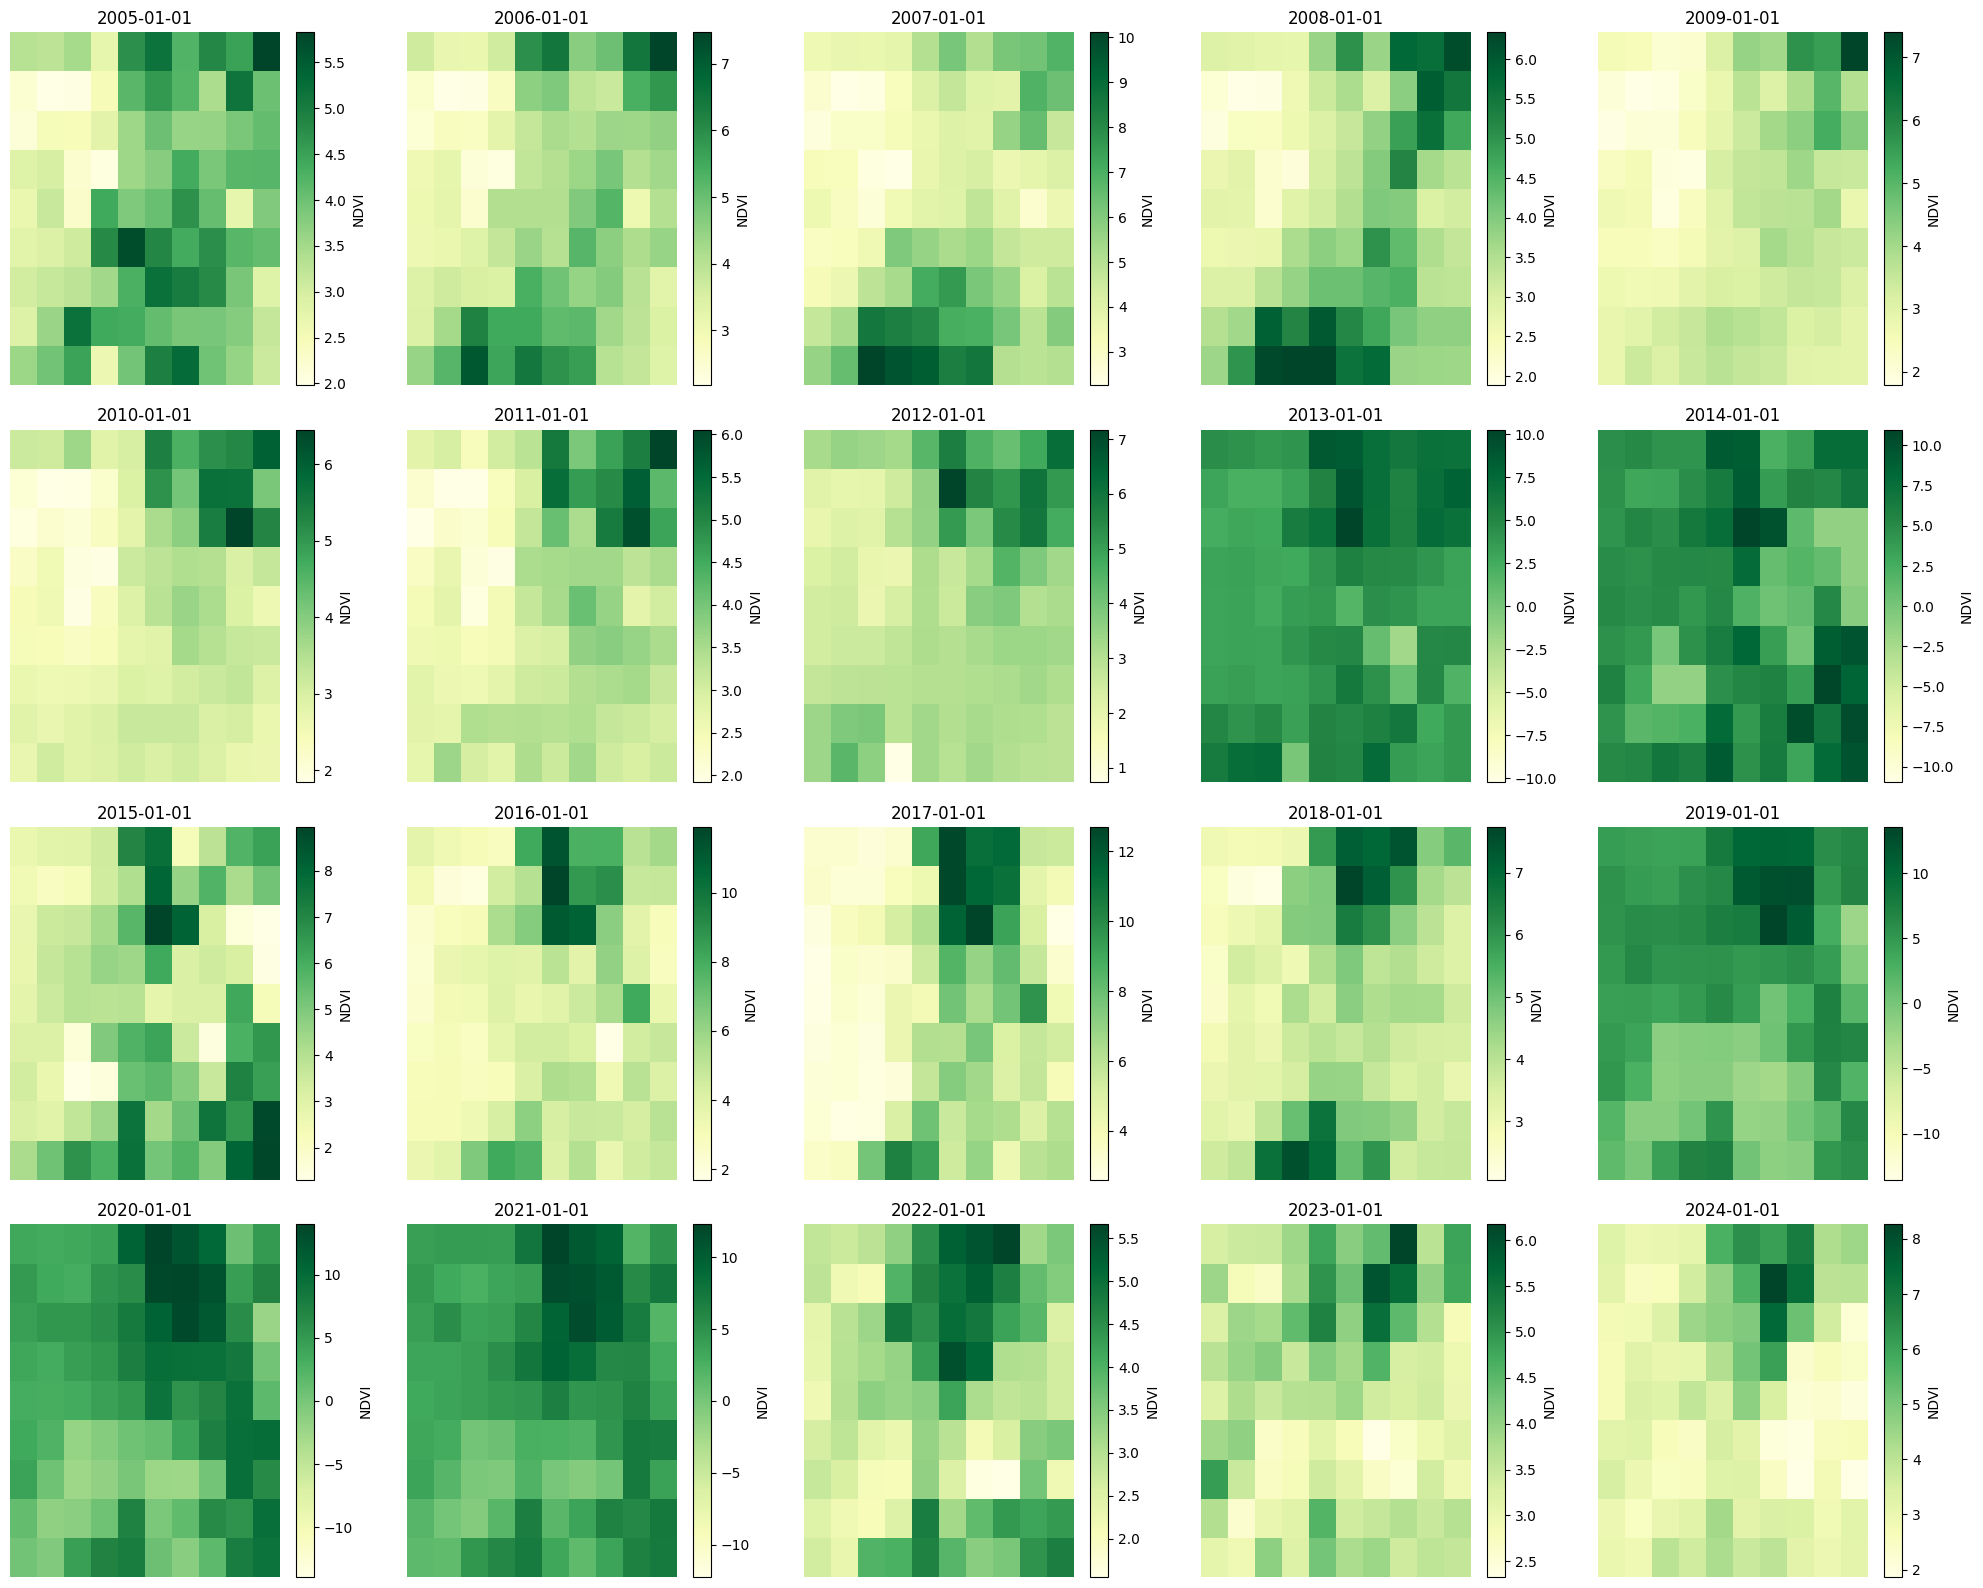

In [53]:
# Ploting NDVI images
# Create a list of 20 NDVI DataArrays from the existing ndivCollcetions dataset

ndivCollcetions = ds['NDVI']
images = [ndivCollcetions.isel(time=i) for i in range(20)] # Creating list of NDVI data

# Create a grid of subplots (e.g., 4 rows × 5 columns)
fig, axes = plt.subplots(4, 5, figsize=(20, 16))

# Flatten axes for easy iteration
axes = axes.flatten()

# Plot each image
for i, ax in enumerate(axes):
    images[i].plot(ax=ax, cmap="YlGn")
    ax.set_title(str(ndivCollcetions.time.values[i])[:10]) # Use original time values for titles
    ax.axis("off")

plt.tight_layout()
plt.show()


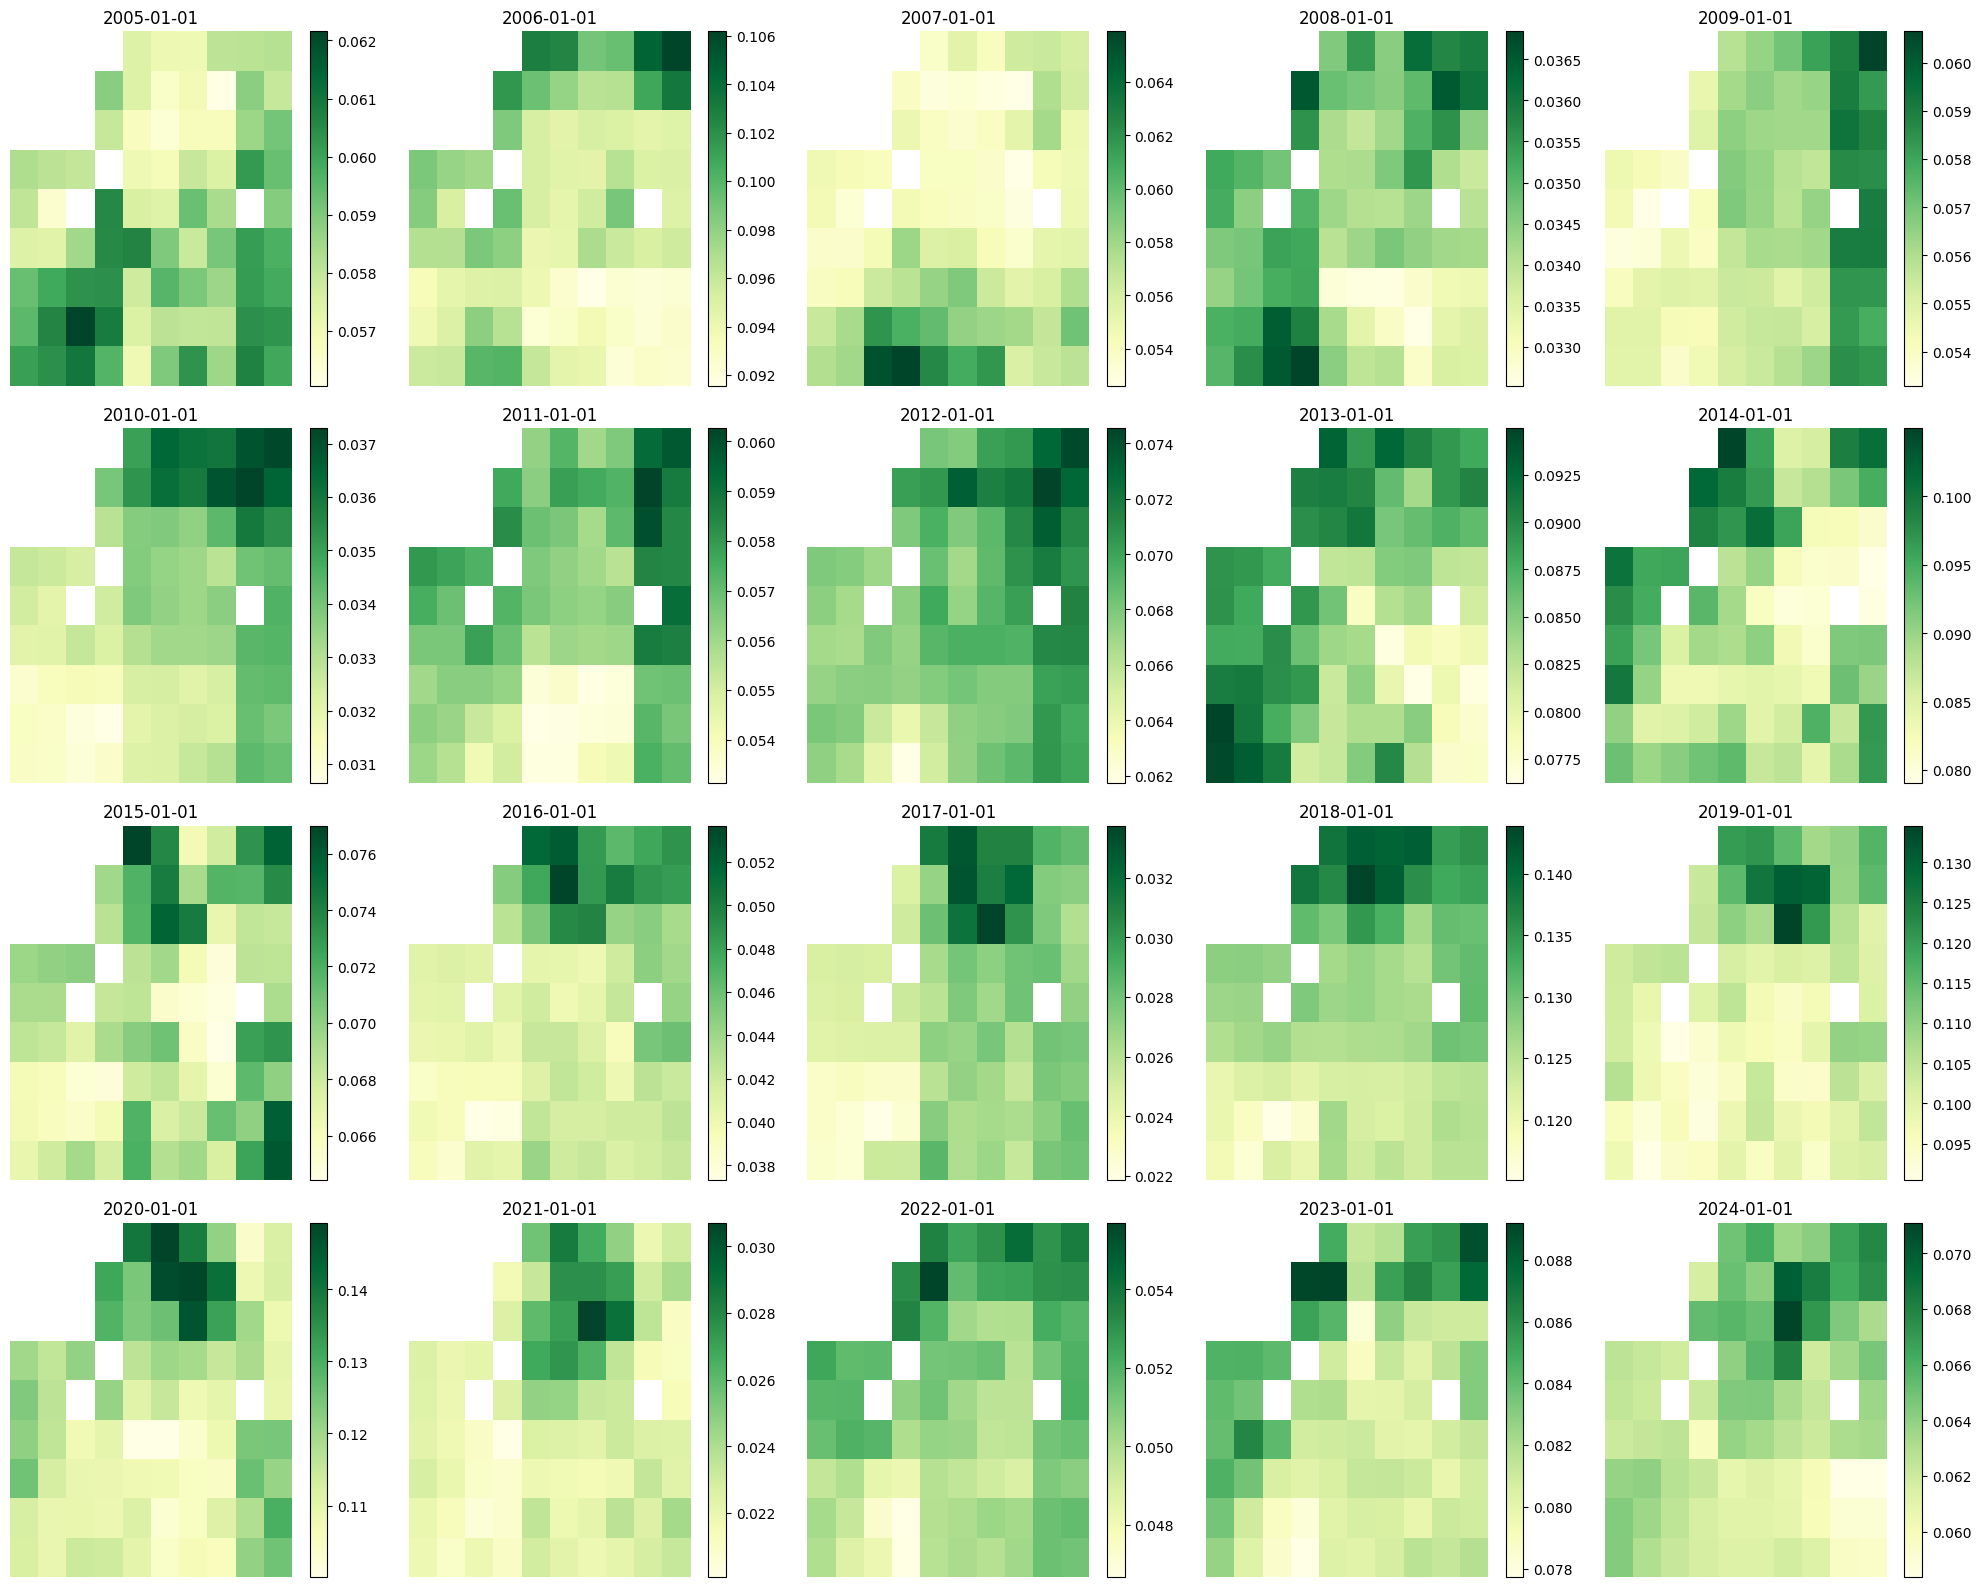

In [54]:
# Measuring and Labeling Aridity, then ploting the aridity map

aridity = ds.precipitation / ds.PET # Measuring the Aridity values befor cleaning data

# Ploting values of aridty
images = [aridity.isel(time=i) for i in range(20)] # Creating list of 20 images
fig, axes = plt.subplots(4, 5, figsize=(20, 16))# Create a grid of subplots (e.g., 4 rows × 5 columns)
axes = axes.flatten() # Flatten axes for easy iteration

# Plot each image
for i, ax in enumerate(axes):
    images[i].plot(ax=ax, cmap="YlGn")
    ax.set_title(str(aridity.time.values[i])[:10]) # Use original time values for titles
    ax.axis("off")

plt.tight_layout()
plt.show()


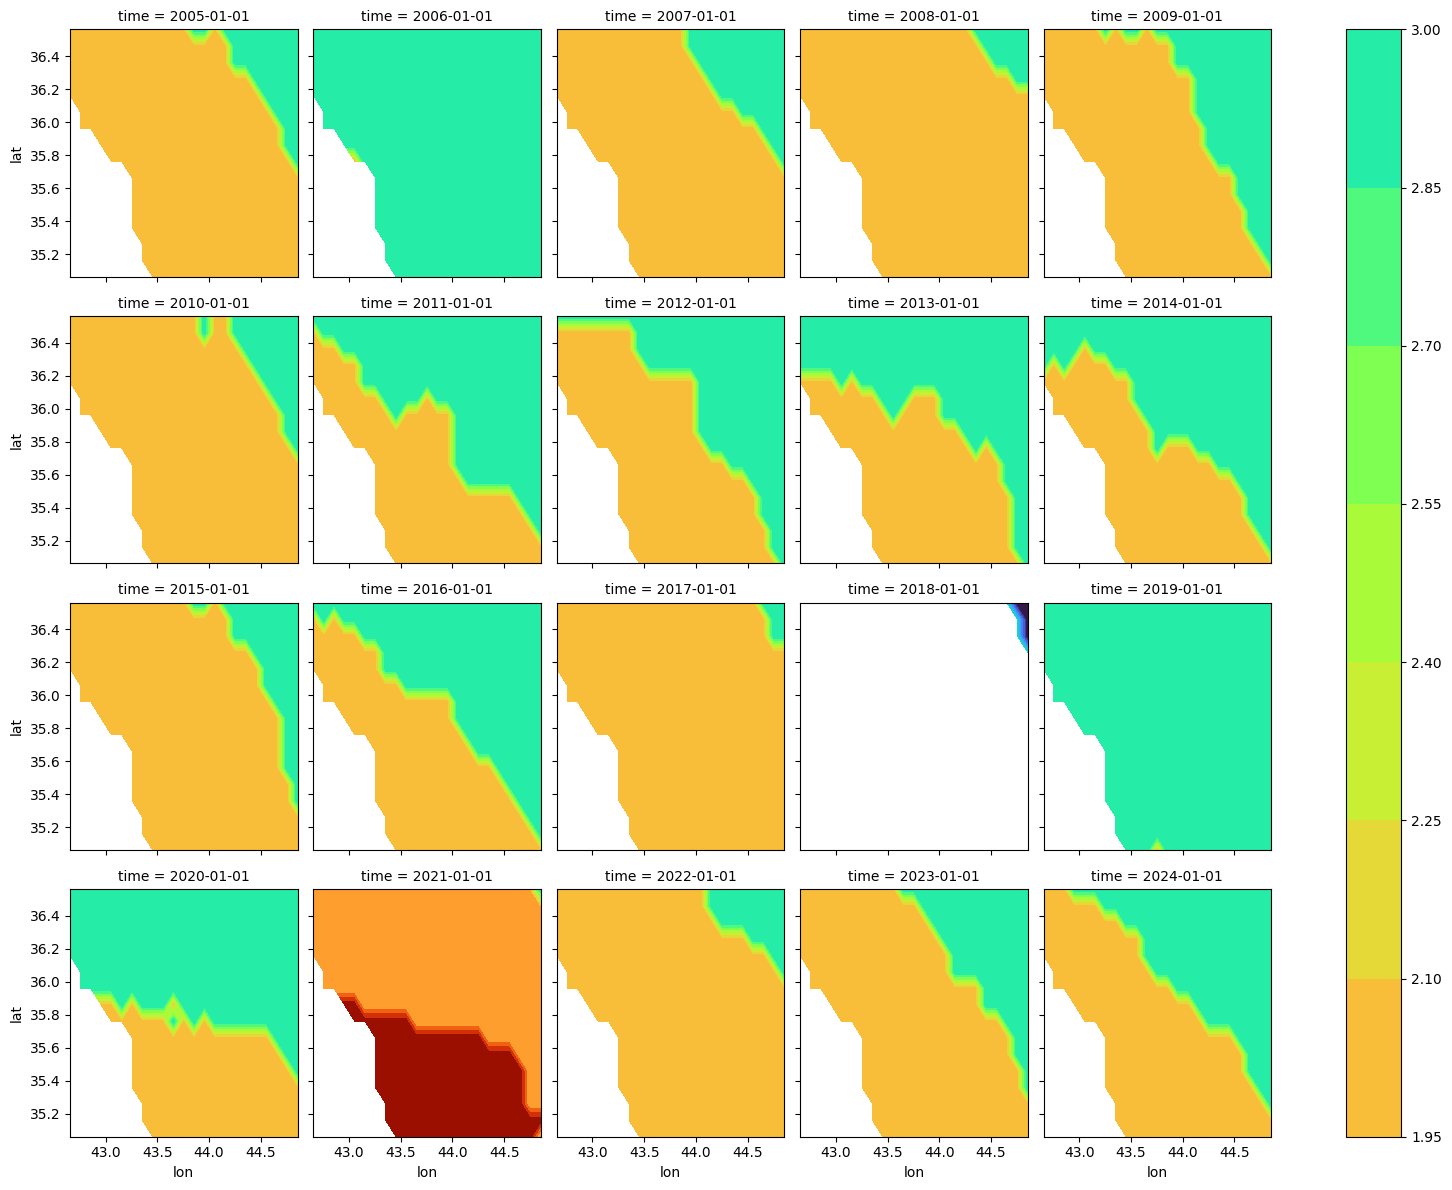

In [ ]:
# Labeling and ploting aridity in a vector layer
aridity_map = xr.where(aridity < 0.05, 1,
                       xr.where(
                           aridity < 0.2, 2,
                           xr.where(
                               aridity < 0.5, 3,
                               xr.where(
                                   aridity < 1, 4, np.nan
                               )
                           )
                       ))

# Ploting vecotor map of the Ardity
aridity_map.plot.contourf(
    x = 'lon',
    y = 'lat',
    col = 'time',
    col_wrap = 5,
    cmap = 'turbo_r'
)

In [ ]:
display(ds) # Displaying data in the dataset

<xarray.Dataset> Size: 89kB
Dimensions:        (time: 20, lon: 23, lat: 16)
Coordinates:
  * time           (time) datetime64[ns] 160B 2005-01-01 ... 2024-01-01
  * lon            (lon) float64 184B 42.65 42.75 42.85 ... 44.65 44.75 44.85
  * lat            (lat) float64 128B 35.06 35.16 35.26 ... 36.36 36.46 36.56
Data variables:
    precipitation  (time, lon, lat) float32 29kB 217.5 221.9 ... 810.3 758.5
    PET            (time, lon, lat) float32 29kB nan nan ... 1.962e+03 1.958e+03
    NDVI           (time, lon, lat) float32 29kB 2.324 2.226 ... 6.725 7.446
Attributes:
    crs:      EPSG:4326

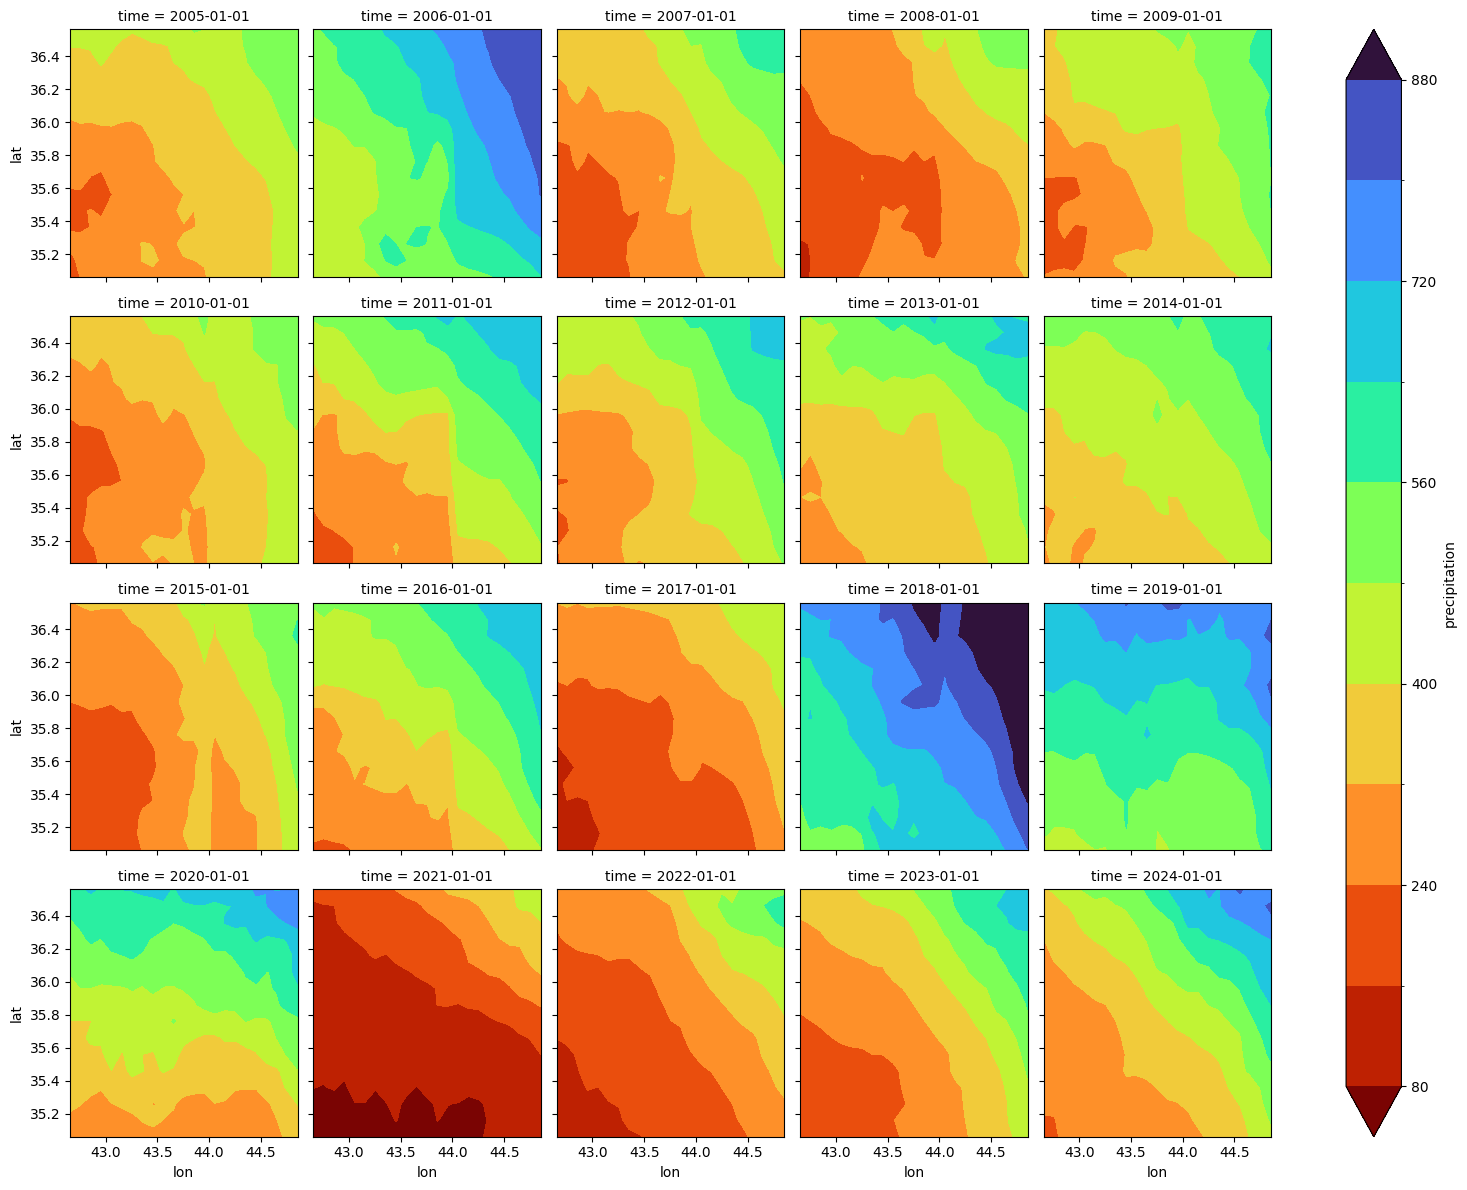

In [ ]:
# Ploting vecotor map of the precipitation
ds['precipitation'].plot.contourf(
    x = 'lon',
    y = 'lat',
    col = 'time',
    col_wrap = 5,
    robust = True,
    levels = 10,
    cmap = 'turbo_r'
)

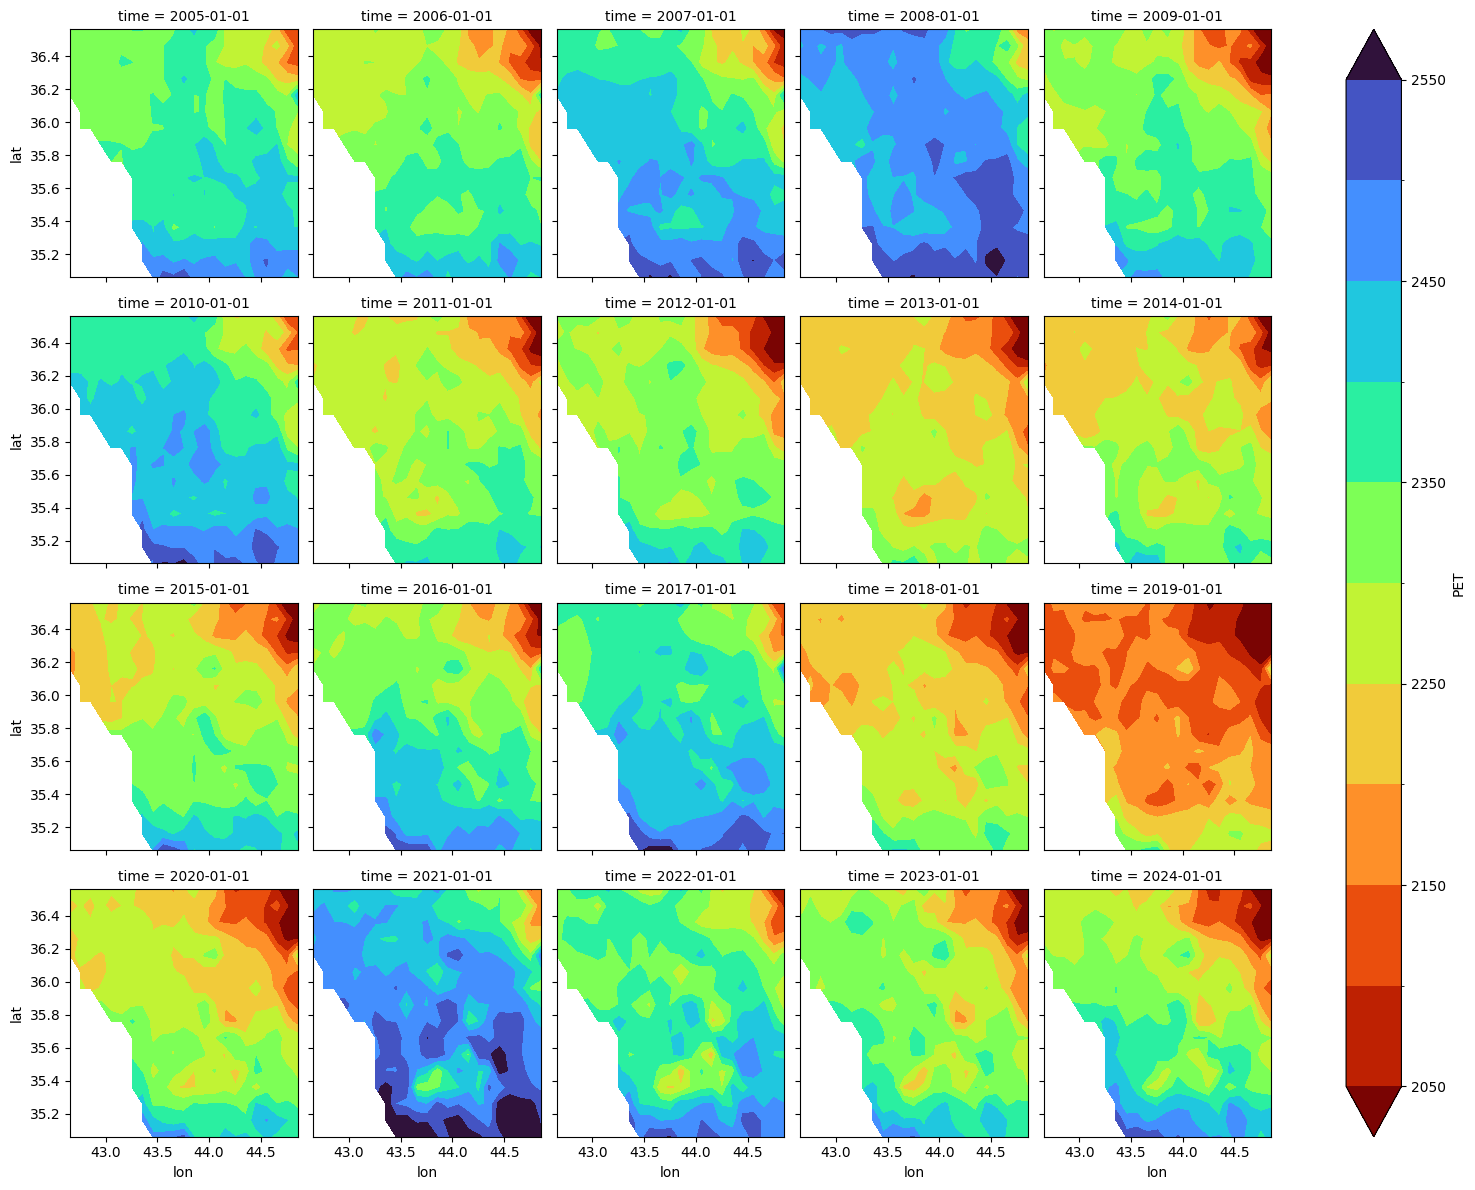

In [ ]:
# Ploting vecotor map of the Potential EvapoTranspiration PET
ds['PET'].plot.contourf(
    x = 'lon',
    y = 'lat',
    col = 'time',
    col_wrap = 5,
    robust = True,
    levels = 10,
    cmap = 'turbo_r'
)

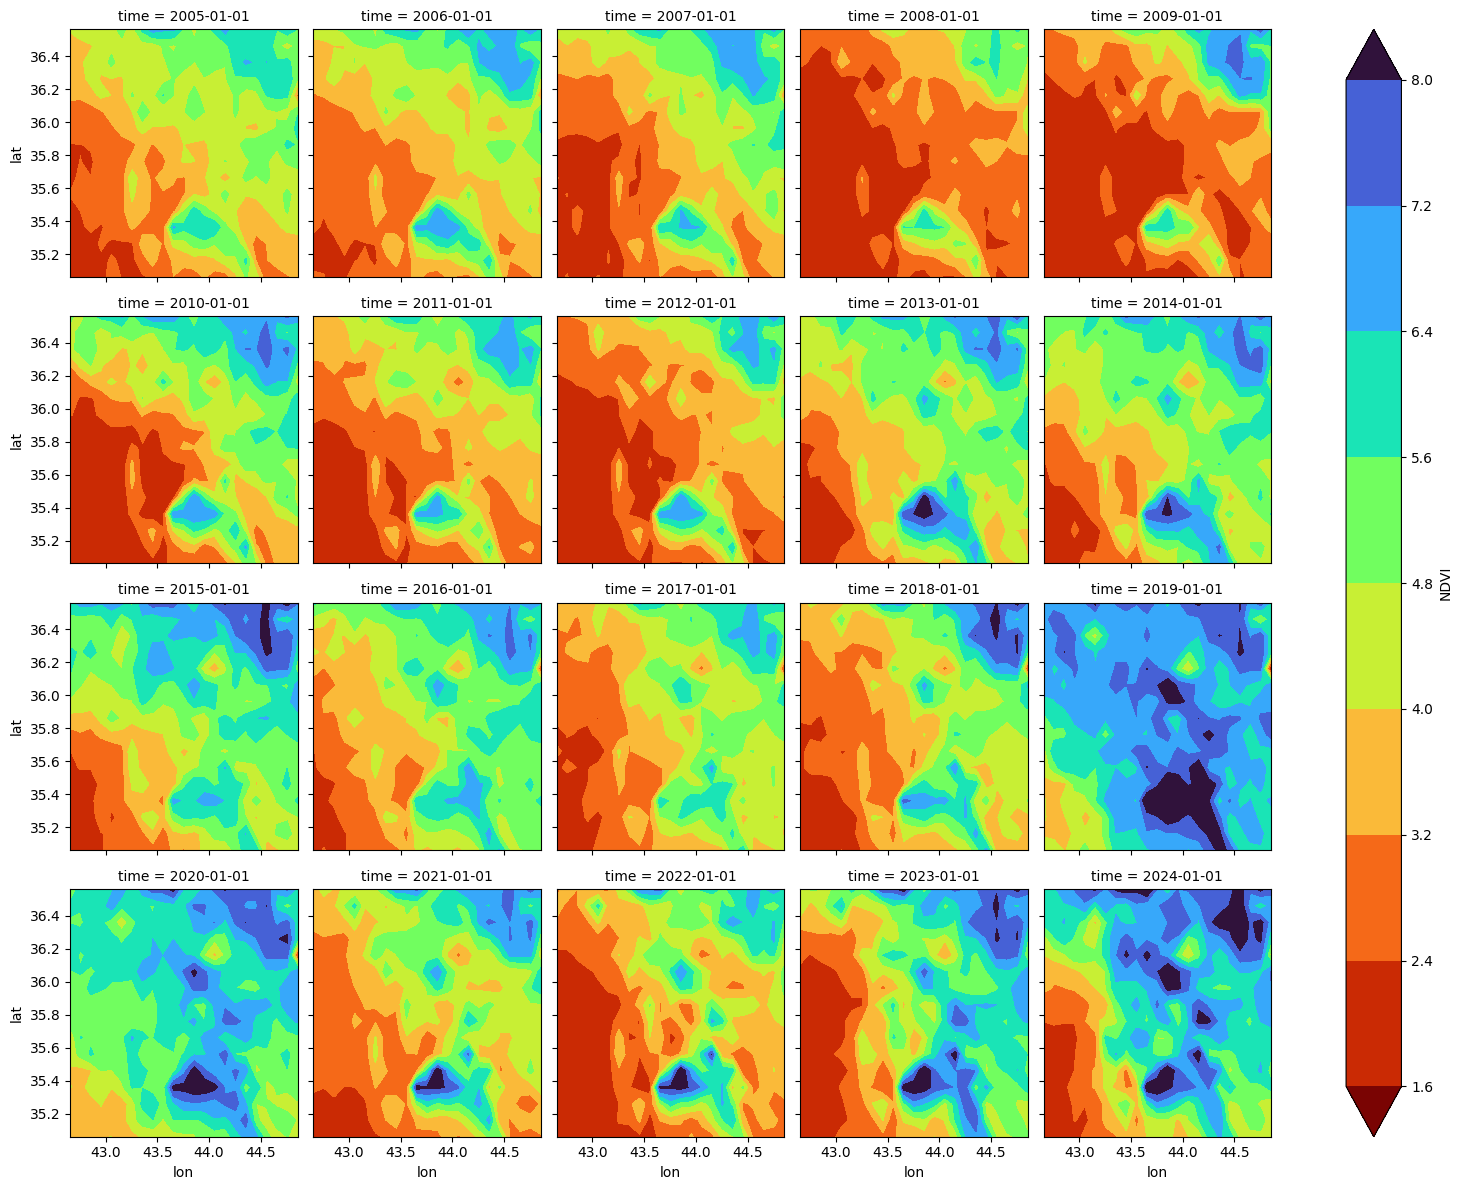

In [ ]:
# Ploting vecotor map of the NDVI
ds['NDVI'].plot.contourf(
    x = 'lon',
    y = 'lat',
    col = 'time',
    col_wrap = 5,
    robust = True,
    levels = 10,
    cmap = 'turbo_r'

)

In [ ]:
# Measuring Vegitation Conditional Index VCI
def compute_vci_combine_ds(ds):

    ndvi = ds['NDVI']
    ndvi_min = ds['NDVI'].min()
    ndvi_max = ds['NDVI'].max()
    vci = (ndvi - ndvi_min) / (ndvi_max - ndvi_min)
    combined_ds_vci = xr.Dataset({
        'VCI': vci,
        'NDVI': ndvi,
        'PET': ds['PET'],
        'precipitation': ds['precipitation']
    })

    return combined_ds_vci

vci_collection = compute_vci_combine_ds(ds) # Combining VCI with dataset

In [ ]:
# Sorting data
vci_ndvi_pet_pre_ds= vci_collection.sortby('time') * 1

In [ ]:
vci_ndvi_pet_pre_ds

<xarray.Dataset> Size: 148kB
Dimensions:        (time: 20, lon: 23, lat: 16)
Coordinates:
  * time           (time) datetime64[ns] 160B 2005-01-01 ... 2024-01-01
  * lon            (lon) float64 184B 42.65 42.75 42.85 ... 44.65 44.75 44.85
  * lat            (lat) float64 128B 35.06 35.16 35.26 ... 36.36 36.46 36.56
Data variables:
    VCI            (time, lon, lat) float64 59kB 0.122 0.1106 ... 0.6313 0.7148
    NDVI           (time, lon, lat) float32 29kB 2.324 2.226 ... 6.725 7.446
    PET            (time, lon, lat) float32 29kB nan nan ... 1.962e+03 1.958e+03
    precipitation  (time, lon, lat) float32 29kB 217.5 221.9 ... 810.3 758.5

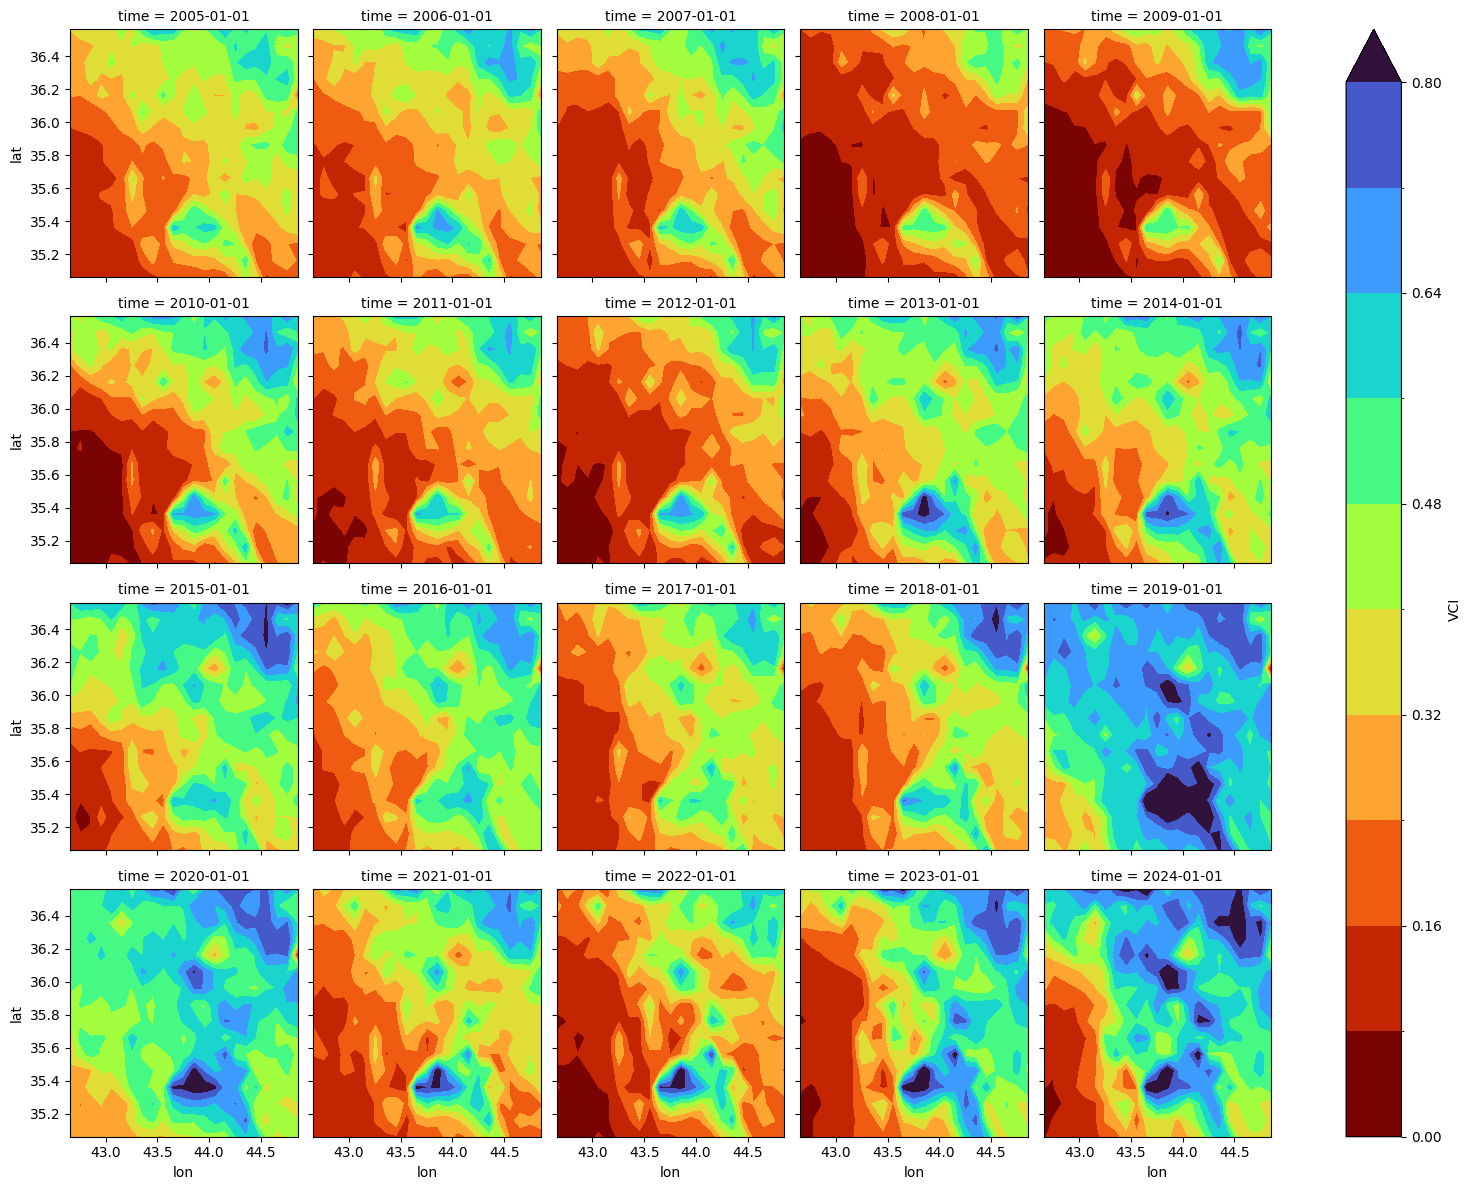

In [ ]:
# Testing the content of the dataset
vci_ndvi_pet_pre_ds['VCI'].plot.contourf(
    x = 'lon',
    y = 'lat',
    col = 'time',
    col_wrap = 5,
    robust = True,
    levels = 10,
    cmap = 'turbo_r'
)

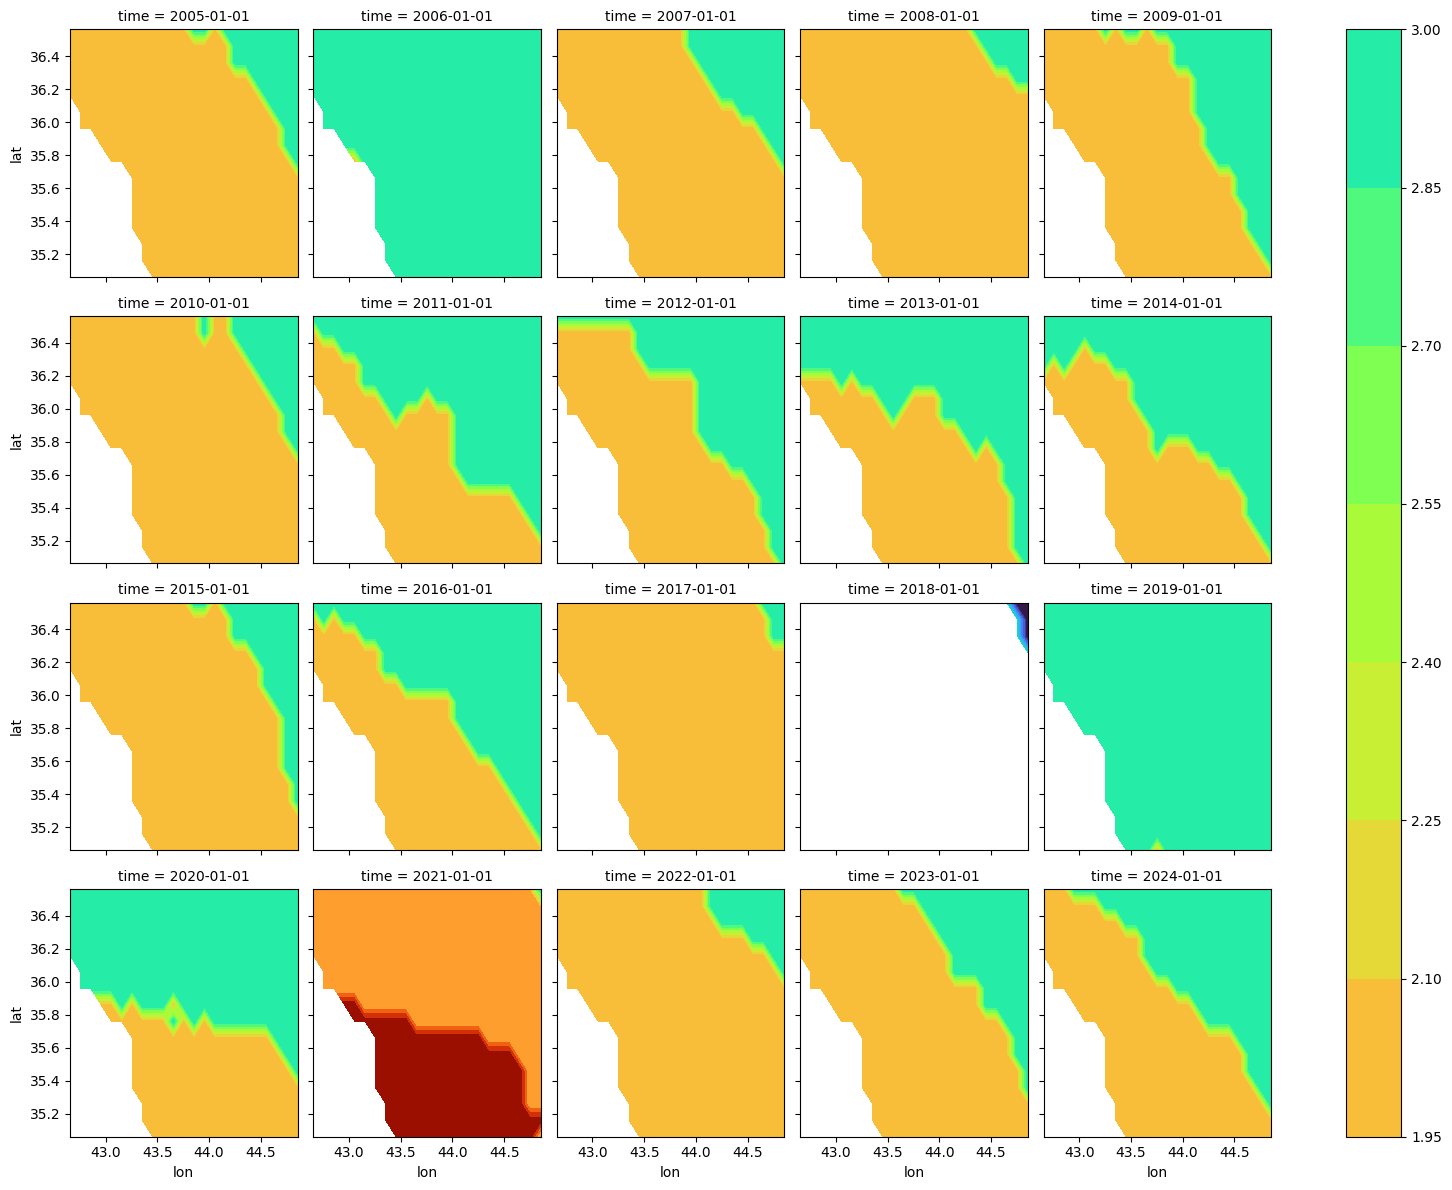

In [ ]:
# Engineering data (dataset) for the Deep Learning (multivariant regression) model

from sklearn.preprocessing import StandardScaler

# --- Step 1: Sort by time, lon, and lat ---
ds = vci_ndvi_pet_pre_ds.sortby("time")
ds = vci_ndvi_pet_pre_ds.sortby("lon")
ds = vci_ndvi_pet_pre_ds.sortby("lat")

# --- Step 2: Handle missing values ---
# Option A: Drop NaNs
ds_clean = ds.where(ds.notnull(), drop=True)

# Option B: Fill NaNs with 0 (or another strategy)
#ds_clean = ds.fillna(0)


# --- Step 3: Flatten dataset ---
# Flatten (time, lon, lat) into one dimension, keep metrics as the second dimension
values = ds_clean.to_array().transpose('time', 'lon', 'lat', ...).values.reshape(-1, len(ds_clean.data_vars))

# --- Step 4: Normalize metrics ---
scaler = StandardScaler()
scaled_values = scaler.fit_transform(values)

# --- Step 5: Convert back to DataArray ---
# Reshape back to (time, lon, lat, metric) dimensions
ds_vector = xr.DataArray(
    scaled_values.reshape(ds_clean.time.size, ds_clean.lon.size, ds_clean.lat.size, len(ds_clean.data_vars)),
    dims=["time", "lon", "lat", "metric"],
    coords={
        "time": ds_clean.time,
        "lon": ds_clean.lon,
        "lat": ds_clean.lat,
        "metric": list(ds_clean.data_vars)
    }
)

# --- Step 6: Example derived metric (Aridity Index), where this is after cleaning data ---
aridity = ds_clean["precipitation"] / ds_clean["PET"]

aridity_map = xr.where(aridity < 0.05, 1,
                       xr.where(aridity < 0.2, 2,
                       xr.where(aridity < 0.5, 3,
                       xr.where(aridity < 1, 4, np.nan))))

# --- Step 7: Visualization Aridity---
aridity_map.plot.contourf(
    x="lon",
    y="lat",
    col="time",
    col_wrap=5,
    cmap="turbo_r"
)

In [ ]:
# Print a summary of the Dataset (its structure, coordinates, and data variables)
display(ds)

<xarray.Dataset> Size: 148kB
Dimensions:        (time: 20, lon: 23, lat: 16)
Coordinates:
  * time           (time) datetime64[ns] 160B 2005-01-01 ... 2024-01-01
  * lon            (lon) float64 184B 42.65 42.75 42.85 ... 44.65 44.75 44.85
  * lat            (lat) float64 128B 35.06 35.16 35.26 ... 36.36 36.46 36.56
Data variables:
    VCI            (time, lon, lat) float64 59kB 0.122 0.1106 ... 0.6313 0.7148
    NDVI           (time, lon, lat) float32 29kB 2.324 2.226 ... 6.725 7.446
    PET            (time, lon, lat) float32 29kB nan nan ... 1.962e+03 1.958e+03
    precipitation  (time, lon, lat) float32 29kB 217.5 221.9 ... 810.3 758.5

In [ ]:
ds.info()

xarray.Dataset {
dimensions:
	time = 20 ;
	lon = 23 ;
	lat = 16 ;

variables:
	datetime64[ns] time(time) ;
	float64 lon(lon) ;
	float64 lat(lat) ;
	float64 VCI(time, lon, lat) ;
		VCI:id = NDVI ;
		VCI:data_type = {'type': 'PixelType', 'precision': 'double'} ;
		VCI:crs = EPSG:4326 ;
		VCI:crs_transform = [1, 0, 0, 0, 1, 0] ;
	float32 NDVI(time, lon, lat) ;
		NDVI:id = NDVI ;
		NDVI:data_type = {'type': 'PixelType', 'precision': 'double'} ;
		NDVI:crs = EPSG:4326 ;
		NDVI:crs_transform = [1, 0, 0, 0, 1, 0] ;
	float32 PET(time, lon, lat) ;
		PET:id = PET ;
		PET:data_type = {'type': 'PixelType', 'precision': 'double'} ;
		PET:crs = EPSG:4326 ;
		PET:crs_transform = [1, 0, 0, 0, 1, 0] ;
	float32 precipitation(time, lon, lat) ;
		precipitation:id = precipitation ;
		precipitation:data_type = {'type': 'PixelType', 'precision': 'double'} ;
		precipitation:crs = EPSG:4326 ;
		precipitation:crs_transform = [1, 0, 0, 0, 1, 0] ;

// global attributes:
}

In [ ]:
# View the coordinates of the Dataset
display(ds.coords)

Coordinates:
  * time     (time) datetime64[ns] 160B 2005-01-01 2006-01-01 ... 2024-01-01
  * lon      (lon) float64 184B 42.65 42.75 42.85 42.95 ... 44.65 44.75 44.85
  * lat      (lat) float64 128B 35.06 35.16 35.26 35.36 ... 36.36 36.46 36.56

In [ ]:
# View the data variables within the Dataset
display(ds.data_vars)

Data variables:
    VCI            (time, lon, lat) float64 59kB 0.122 0.1106 ... 0.6313 0.7148
    NDVI           (time, lon, lat) float32 29kB 2.324 2.226 ... 6.725 7.446
    PET            (time, lon, lat) float32 29kB nan nan ... 1.962e+03 1.958e+03
    precipitation  (time, lon, lat) float32 29kB 217.5 221.9 ... 810.3 758.5

Now, flatten the combineData Dataset. Here, the stack the spatial dimensions (lon and lat) will be made and then convert the result into a pandas DataFrame. Also handle any missing values by dropping them.

In [ ]:
import pandas as pd

# Stack 'lon' and 'lat' dimensions to create a new 'location' dimension
# This converts the spatial data into a long format for each time step.
flattened_data = ds.stack(location=('lon', 'lat'))

# Convert the xarray DataArray into a pandas DataFrame
# This reshapes the data to (time * location, features)
df_flattened = flattened_data.to_dataframe()

# Reset index to make 'time' and 'location' (lon, lat) regular columns
df_flattened = df_flattened.reset_index()

# Drop rows with any NaN values, as deep learning models typically don't handle them directly
df_flattened = df_flattened.dropna()

# Display the first few rows of the flattened DataFrame
display(df_flattened.head())

,time,lon,lat,VCI,NDVI,PET,precipitation
11,2005-01-01,42.65498,36.162002,0.247920,3.4125,2318.000000,362.810028
12,2005-01-01,42.65498,36.262002,0.306022,3.9145,2296.100098,373.760010
13,2005-01-01,42.65498,36.362002,0.304460,3.9010,2319.300049,380.330017
14,2005-01-01,42.65498,36.462002,0.292353,3.7964,2327.699951,402.230011
15,2005-01-01,42.65498,36.562002,0.321913,4.0518,2326.399902,420.480011


In [ ]:
import numpy as np

# Calculate the Aridity Index
# Aridity Index is defined as Precipitation / PET.
# Handle potential division by zero (if PET is 0) by replacing infinities with NaN, then filling NaNs with the mean.
df_flattened['aridity_index'] = df_flattened['precipitation'] / df_flattened['PET']
df_flattened['aridity_index'] = df_flattened['aridity_index'].replace([np.inf, -np.inf], np.nan)

# Fill any NaNs that might result from division by zero or initial NaNs in PET
# with the mean of the aridity_index column.
if df_flattened['aridity_index'].isnull().any():
    df_flattened['aridity_index'] = df_flattened['aridity_index'].fillna(df_flattened['aridity_index'].mean())


# Define drought labels based on Aridity Index thresholds
# A common classification is used, adjusted to define drought severity levels from 0 (no drought) to 4 (extreme drought).
df_flattened['drought_label'] = np.select(
    [
        (df_flattened['aridity_index'] < 0.05), # Extreme Drought
        (df_flattened['aridity_index'] >= 0.05) & (df_flattened['aridity_index'] < 0.2), # Severe Drought
        (df_flattened['aridity_index'] >= 0.2) & (df_flattened['aridity_index'] < 0.5), # Moderate Drought
        (df_flattened['aridity_index'] >= 0.5) & (df_flattened['aridity_index'] < 1.0)  # Mild Drought
    ],
    [4, 3, 2, 1], # Assigning labels: 4 (Extreme) -> 3 (Severe) -> 2 (Moderate) -> 1 (Mild)
    default=0 # Default label for Aridity Index >= 1.0 (No Drought)
)

# Analyze Label Distribution
print("\nDrought Label Distribution:")
# Display the count of each drought label to check for class imbalance.
display(df_flattened['drought_label'].value_counts().sort_index())

# Final Task: Confirm that the drought labels have been successfully created and are integrated.
print("\nDataFrame with Aridity Index and Drought Label (first 5 rows):")
display(df_flattened[['time', 'lon', 'lat', 'NDVI', 'precipitation', 'PET', 'aridity_index', 'drought_label']].head())


Drought Label Distribution:


,count
drought_label,
1,4
2,2448
3,3701
4,107



DataFrame with Aridity Index and Drought Label (first 5 rows):


,time,lon,lat,NDVI,precipitation,PET,aridity_index,drought_label
11,2005-01-01,42.65498,36.162002,3.4125,362.810028,2318.000000,0.156519,3
12,2005-01-01,42.65498,36.262002,3.9145,373.760010,2296.100098,0.162780,3
13,2005-01-01,42.65498,36.362002,3.9010,380.330017,2319.300049,0.163985,3
14,2005-01-01,42.65498,36.462002,3.7964,402.230011,2327.699951,0.172801,3
15,2005-01-01,42.65498,36.562002,4.0518,420.480011,2326.399902,0.180743,3


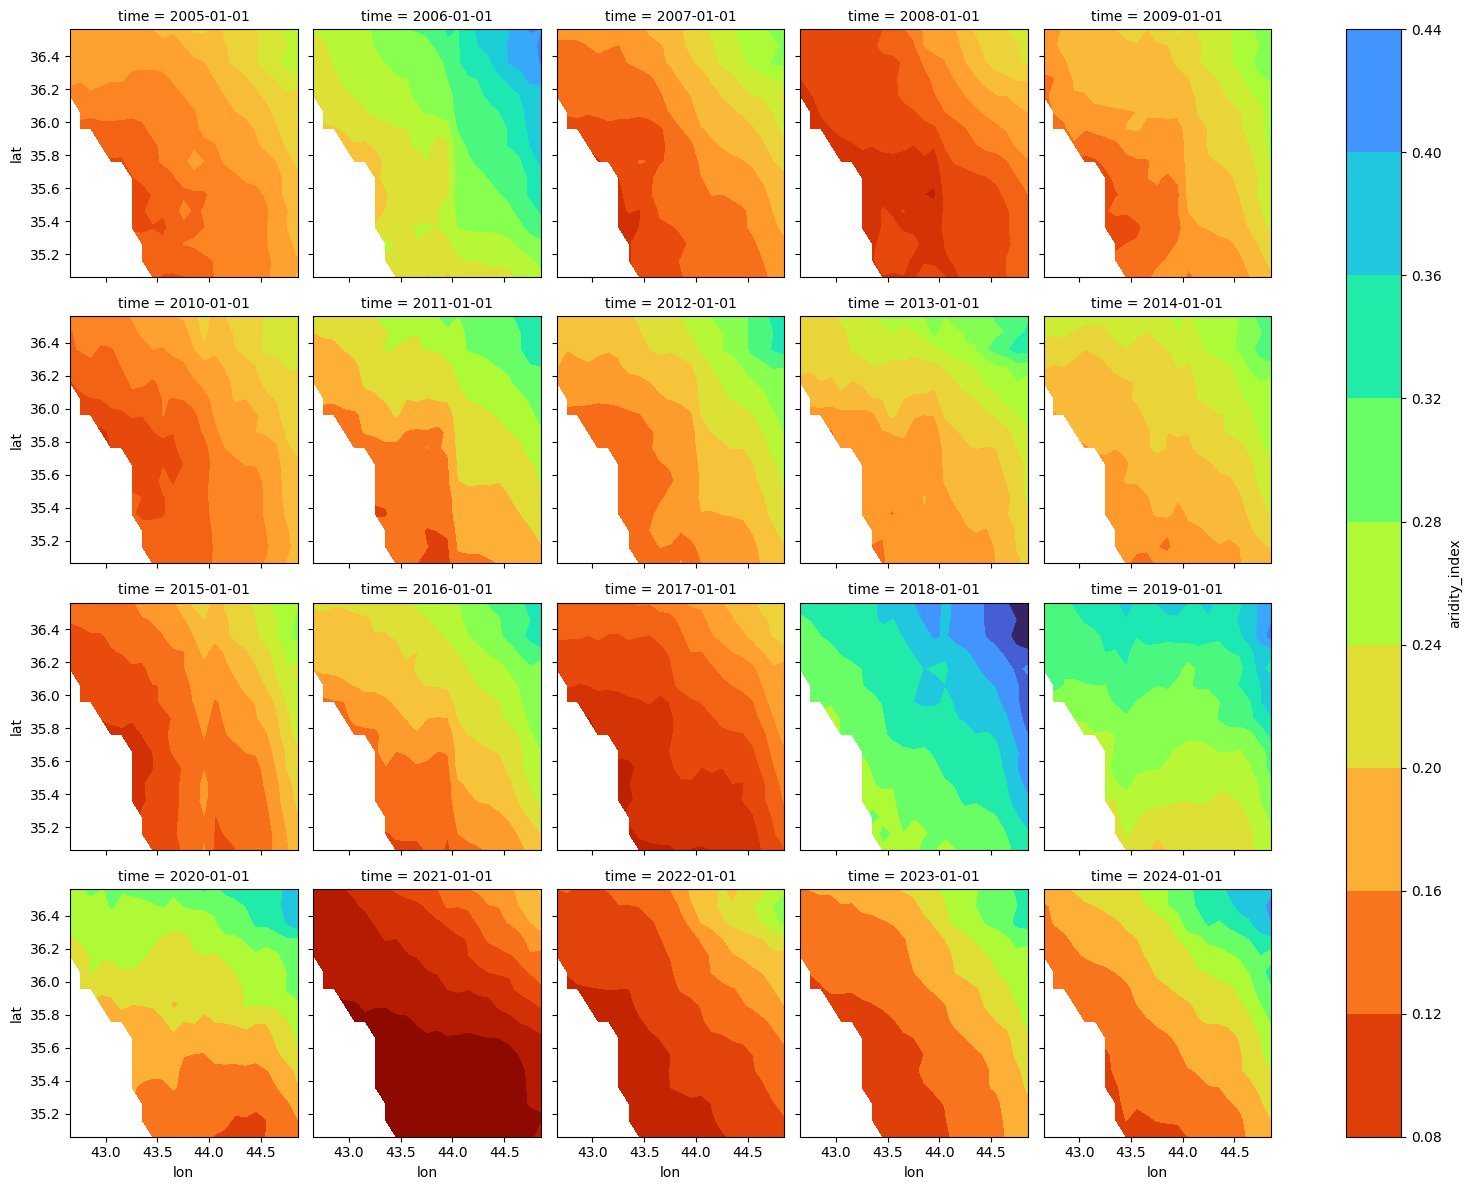

In [ ]:
# Ploting the Aridity map after cleaning missing data (Nan) in PET variable
# Convert the aridity_index column from df_flattened back to an xarray DataArray for plotting
aridity_for_plot = df_flattened.set_index(['time', 'lon', 'lat'])['aridity_index'].to_xarray()

aridity_for_plot.plot.contourf(
    x="lon",
    y="lat",
    col="time",
    col_wrap=5,
    cmap="turbo_r"
)

The df_flattened DataFrame now contains your combined data in a 2D format, where each row represents a unique combination of time, lon, and lat, and the columns are your features (NDVI, precipitation, PET, and VCI). .

Deep Learning model

In this DL model the univariant regression is used to predict the drought where the Aridity is the y value and vci, ndiv, pet, and precipitation are the x fearures

In [ ]:
# Data preparing for the model
import torch
from sklearn.preprocessing import StandardScaler

# Features (X): NDVI, precipitation, PET, VCI
X = np.stack([
    df_flattened["NDVI"].values,
    df_flattened["precipitation"].values,
    df_flattened["PET"].values,
    df_flattened["VCI"].values
    ], axis=1 )

# Target (Y): Aridity Index
Y = df_flattened["aridity_index"].values.reshape(-1, 1)

# Scale features
x_scaler = StandardScaler()
X_scaled = x_scaler.fit_transform(X)

# Scale target variable
y_scaler = StandardScaler()
Y_scaled = y_scaler.fit_transform(Y)

# Convert to tensors
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
Y_tensor = torch.tensor(Y_scaled, dtype=torch.float32)

In [ ]:
# Defining the regression model (Pytorch model)
import torch.nn as nn
import torch.optim as optim

class AIRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(X.shape[1], 64)   # Updated to match the new number of predictors
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)   # 1 output: Aridity Index

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

model = AIRegression()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

Epoch 0, Loss: 0.9051
Epoch 50, Loss: 0.0014


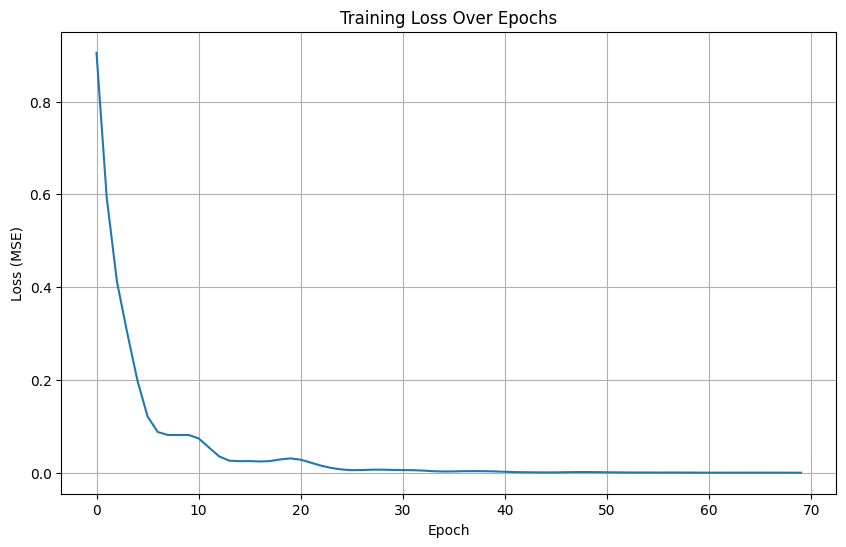

In [ ]:
import matplotlib.pyplot as plt

# Training loop
loss_history = [] # List to store loss at each epoch
for epoch in range(70):
    optimizer.zero_grad()
    outputs = model(X_tensor)
    loss = criterion(outputs, Y_tensor)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item()) # Store loss
    if epoch % 50 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

# Plotting the loss history
plt.figure(figsize=(10, 6))
plt.plot(loss_history)
plt.title('Training Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.grid(True)
plt.show()

In [ ]:
# Evaluating the performance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

preds = outputs.detach().numpy().flatten()
true = Y_tensor.numpy().flatten()

rmse = np.sqrt(mean_squared_error(true, preds))
mae = mean_absolute_error(true, preds)
r2 = r2_score(true, preds)

print(f"Aridity Index → RMSE: {rmse:.3f}, MAE: {mae:.3f}, R²: {r2:.3f}")


Aridity Index → RMSE: 0.020, MAE: 0.014, R²: 1.000


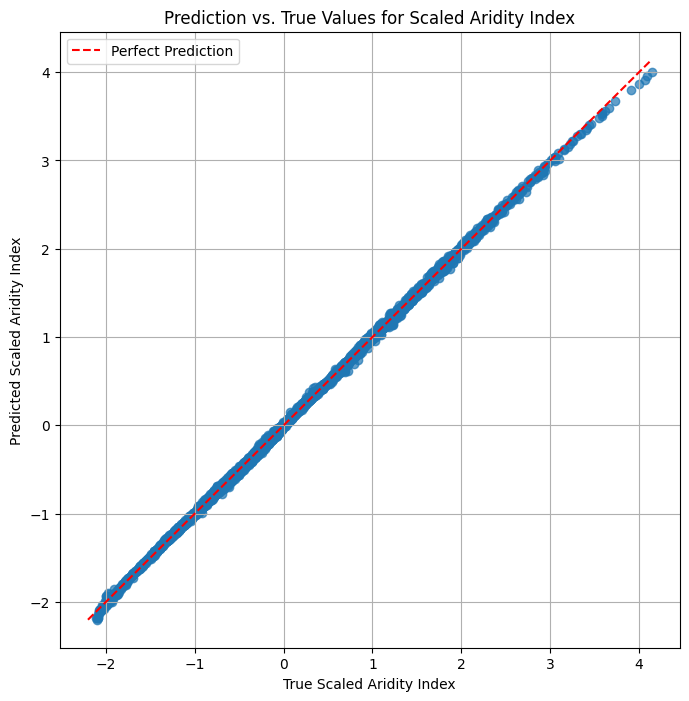

In [ ]:
import matplotlib.pyplot as plt

# Create a scatter plot of true vs. predicted values
plt.figure(figsize=(8, 8))
plt.scatter(true, preds, alpha=0.7)

# Add a diagonal line for perfect prediction
min_val = min(true.min(), preds.min())
max_val = max(true.max(), preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Prediction')

plt.xlabel('True Scaled Aridity Index')
plt.ylabel('Predicted Scaled Aridity Index')
plt.title('Prediction vs. True Values for Scaled Aridity Index')
plt.grid(True)
plt.legend()
plt.show()

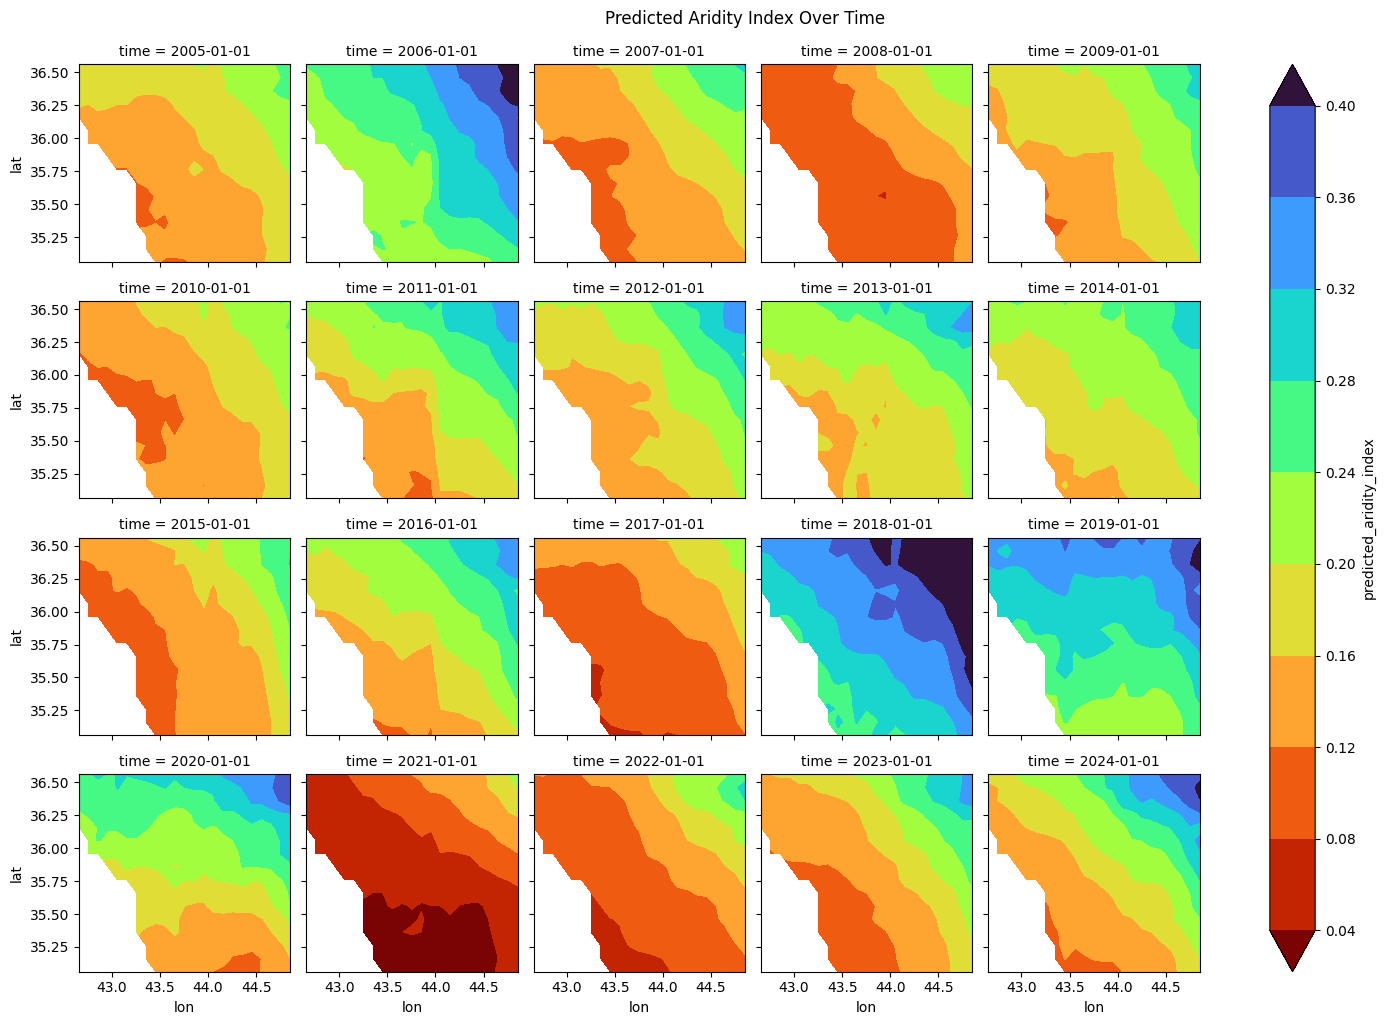

In [ ]:
# Inverse transform the scaled predictions back to their original scale for ploring predicted aridity
unscaled_preds = y_scaler.inverse_transform(preds.reshape(-1, 1)).flatten()

# Create a temporary DataFrame to hold the predicted aridity index with spatial coordinates
df_predicted_aridity = df_flattened[['time', 'lon', 'lat']].copy()
df_predicted_aridity['predicted_aridity_index'] = unscaled_preds

# Convert the temporary DataFrame to an xarray DataArray for plotting
predicted_aridity_for_plot = df_predicted_aridity.set_index(['time', 'lon', 'lat'])['predicted_aridity_index'].to_xarray()

# Plot the predicted Aridity map
predicted_aridity_for_plot.plot.contourf(
    x="lon",
    y="lat",
    col="time",
    col_wrap=5,
    cmap="turbo_r",
    robust=True,
    levels=10,
    figsize=(15, 10)
)

plt.suptitle('Predicted Aridity Index Over Time', y=1.02) # Add a super title
plt.show()

--- Here is another regression model taken from Deep Learning2 book---

In [ ]:
X_np = X_tensor.numpy()
Y_np = Y_tensor.numpy()

In [ ]:
def defin_parmaters(n_wights):
  a = np.random.rand(n_wights, 1) # Changed to (n_wights, 1) to make it a column vector
  b = np.random.rand()
  return a, b

In [ ]:
def predictions(a, b, X):
  z = np.dot(X, a) + b
  return z

In [ ]:
def find_cost(z, y):
    m = y.shape[0]
    total_cost = (1/m)*np.sum(np.square(z-y))
    return total_cost

In [ ]:
def find_derivatives(X, y, z):
    m = y.shape[0]
    dz = (2/m)*(z-y)
    da = np.dot(X.T, dz)
    db = np.sum(dz)
    return da, db

In [ ]:
def update_parameters( a, b, da, db, alpha):
    a = a - alpha*da
    b = b - alpha*db
    return a, b

In [ ]:
# Implementing the mulitvariant regression
def liner_regressionm(X, y, alpha, n_iter):
    error_list = []
    lenw = X.shape[1]
    a, b = defin_parmaters(lenw)
    for i in range(n_iter):
      z = predictions(a, b, X)
      cost = find_cost(z, y)
      error_list.append(cost)
      # Corrected call to find_derivatives
      da, db = find_derivatives(X, y, z)
      a, b = update_parameters( a, b, da, db, alpha)
      if i % 50 == 0:
        print(f"Epoch {i}, Loss: {cost:.4f}")
    return a, b, error_list

In [ ]:
alpha = 0.01
n_iter = 1000
error_list = liner_regressionm(X_np, Y_np, alpha, n_iter)

Epoch 0, Loss: 1.4739
Epoch 50, Loss: 0.1754
Epoch 100, Loss: 0.0431
Epoch 150, Loss: 0.0169
Epoch 200, Loss: 0.0097
Epoch 250, Loss: 0.0068
Epoch 300, Loss: 0.0053
Epoch 350, Loss: 0.0045
Epoch 400, Loss: 0.0040
Epoch 450, Loss: 0.0037
Epoch 500, Loss: 0.0035
Epoch 550, Loss: 0.0034
Epoch 600, Loss: 0.0034
Epoch 650, Loss: 0.0034
Epoch 700, Loss: 0.0033
Epoch 750, Loss: 0.0033
Epoch 800, Loss: 0.0033
Epoch 850, Loss: 0.0033
Epoch 900, Loss: 0.0033
Epoch 950, Loss: 0.0033


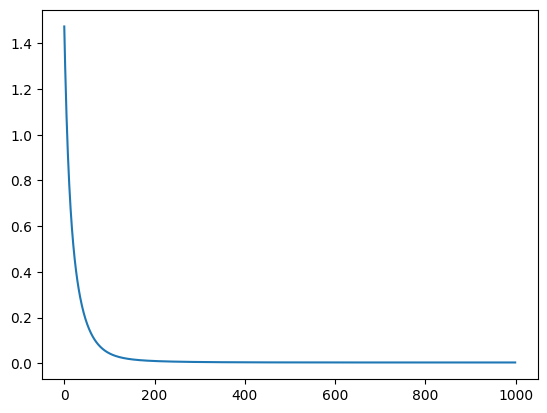

In [ ]:
plt.plot(error_list[2])

In [ ]:

error_list = liner_regressionm(X_np, Y_np, alpha, n_iter)

Epoch 0, Loss: 2.1118
Epoch 50, Loss: 0.3625
Epoch 100, Loss: 0.0745
Epoch 150, Loss: 0.0220
Epoch 200, Loss: 0.0104
Epoch 250, Loss: 0.0068
Epoch 300, Loss: 0.0053
Epoch 350, Loss: 0.0045
Epoch 400, Loss: 0.0040
Epoch 450, Loss: 0.0037
Epoch 500, Loss: 0.0035
Epoch 550, Loss: 0.0034
Epoch 600, Loss: 0.0034
Epoch 650, Loss: 0.0034
Epoch 700, Loss: 0.0033
Epoch 750, Loss: 0.0033
Epoch 800, Loss: 0.0033
Epoch 850, Loss: 0.0033
Epoch 900, Loss: 0.0033
Epoch 950, Loss: 0.0033


In [ ]:
# The liner_regressionm function returns (a, b, error_list).
# We need 'a' (weights) and 'b' (bias) for predictions.
# Assuming 'liner_regressionm' has been run and its output is stored in 'error_list' as a tuple.
# Let's extract 'a' and 'b' from the last run of liner_regressionm.

# Note: 'error_list' is a tuple (a, b, actual_error_list)
a_trained = error_list[0]
b_trained = error_list[1]

# Use the trained 'a' and 'b' to make predictions on the scaled features (X_np)
# The 'predictions' function was previously defined.
z_predicted_scaled = predictions(a_trained, b_trained, X_np)

# Inverse transform the scaled predictions to get them in the original aridity index scale
unscaled_predictions = y_scaler.inverse_transform(z_predicted_scaled)

# Inverse transform the original scaled target (Y_np) for comparison
unscaled_actual_Y = y_scaler.inverse_transform(Y_np)

print("First 5 Unscaled Predictions:")
print(unscaled_predictions[:5].flatten())

print("\nFirst 5 Actual Unscaled Aridity Index Values:")
print(unscaled_actual_Y[:5].flatten())


First 5 Unscaled Predictions:
[0.15869734 0.16545252 0.16631549 0.17510584 0.1832165 ]

First 5 Actual Unscaled Aridity Index Values:
[0.15651856 0.16278036 0.16398482 0.17280148 0.18074279]


Custom Linear Regression Model Evaluation (Unscaled Values):
RMSE: 0.004
MAE: 0.003
R-squared: 0.997


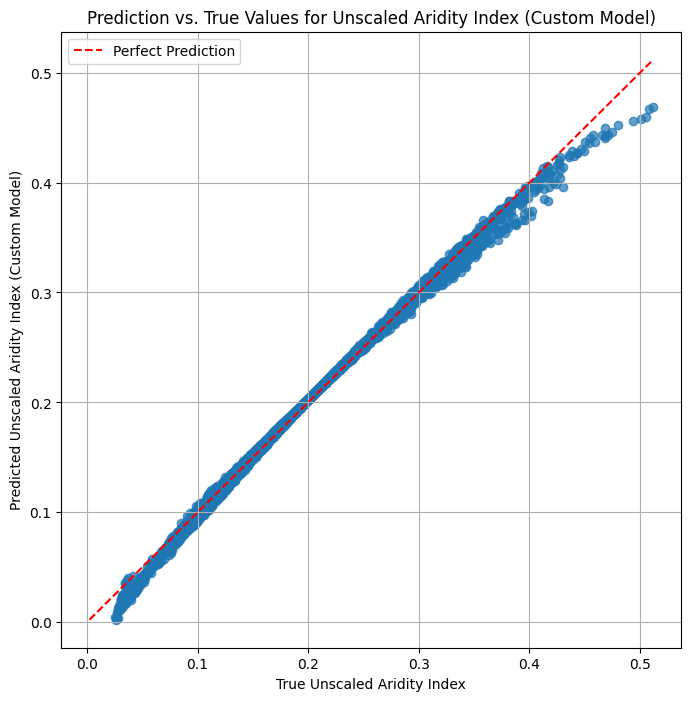

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Evaluate the performance of the custom linear regression model
rmse_custom = np.sqrt(mean_squared_error(unscaled_actual_Y, unscaled_predictions))
mae_custom = mean_absolute_error(unscaled_actual_Y, unscaled_predictions)
r2_custom = r2_score(unscaled_actual_Y, unscaled_predictions)

print(f"Custom Linear Regression Model Evaluation (Unscaled Values):")
print(f"RMSE: {rmse_custom:.3f}")
print(f"MAE: {mae_custom:.3f}")
print(f"R-squared: {r2_custom:.3f}")

# Plotting the predicted vs actual values for the custom model
plt.figure(figsize=(8, 8))
plt.scatter(unscaled_actual_Y, unscaled_predictions, alpha=0.7)

min_val = min(unscaled_actual_Y.min(), unscaled_predictions.min())
max_val = max(unscaled_actual_Y.max(), unscaled_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Prediction')

plt.xlabel('True Unscaled Aridity Index')
plt.ylabel('Predicted Unscaled Aridity Index (Custom Model)')
plt.title('Prediction vs. True Values for Unscaled Aridity Index (Custom Model)')
plt.grid(True)
plt.legend()
plt.show()


Visualize the predicted aridity index from df_predicted_aridit

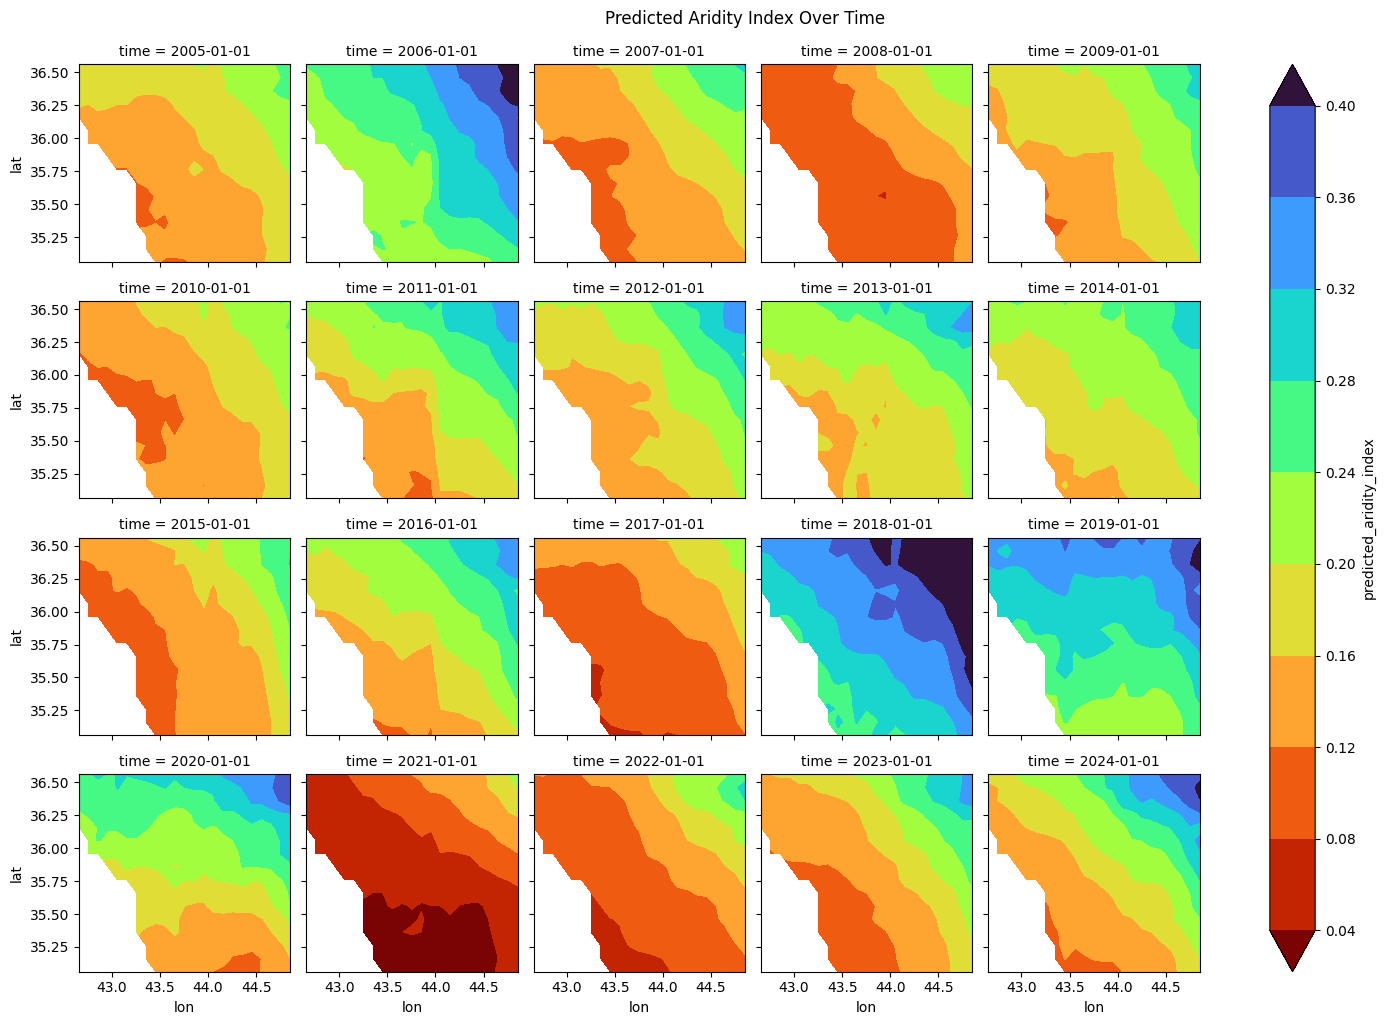

In [ ]:
# Inverse transform the scaled predictions back to their original scale
unscaled_preds = y_scaler.inverse_transform(preds.reshape(-1, 1)).flatten()

# Create a temporary DataFrame to hold the predicted aridity index with spatial coordinates
df_predicted_aridity = df_flattened[['time', 'lon', 'lat']].copy()
df_predicted_aridity['predicted_aridity_index'] = unscaled_preds

# Convert the temporary DataFrame to an xarray DataArray for plotting
predicted_aridity_for_plot = df_predicted_aridity.set_index(['time', 'lon', 'lat'])['predicted_aridity_index'].to_xarray()

# Plot the predicted Aridity map
predicted_aridity_for_plot.plot.contourf(
    x="lon",
    y="lat",
    col="time",
    col_wrap=5,
    cmap="turbo_r",
    robust=True,
    levels=10,
    figsize=(15, 10)
)

plt.suptitle('Predicted Aridity Index Over Time', y=1.02) # Add a super title
plt.show()

Here is the visulizing sesction

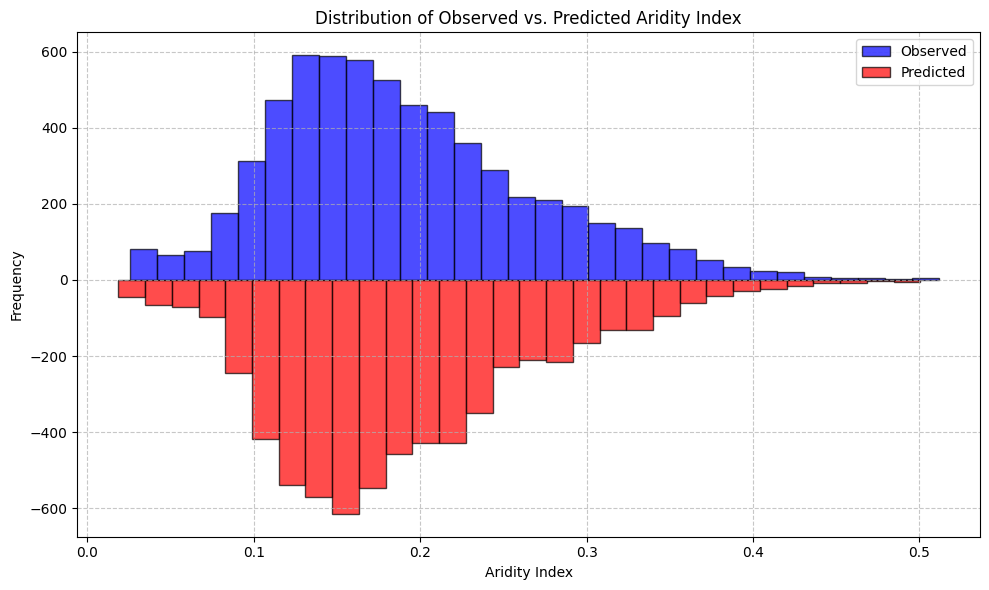

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Sample Data
# Flatten the 3D DataArray to a 1D array of values for histogram plotting
observed = df_flattened["aridity_index"].values.flatten()
predicted = df_predicted_aridity['predicted_aridity_index'].values.flatten()

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(observed, bins=30, color='blue', edgecolor='black', alpha=0.7, label='Observed')
ax.hist(predicted, bins=30, color='red', edgecolor='black', alpha=0.7, label='Predicted', weights=-np.ones_like(predicted))

ax.set_title('Distribution of Observed vs. Predicted Aridity Index')
ax.set_xlabel('Aridity Index')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Saving data
df_flattened.to_csv('my_df.csv', index=False)
df_predicted_aridity.to_csv('my_Predicted_df.csv', index=False)

In [ ]:
df_2022 = df_flattened[df_flattened['time'].dt.year == 2022]

In [ ]:
aridity_2022['mid_dorught'] = aridity_2022['drought_label'].where(aridity_2022['drought_label'] == 2)

NameError: name 'aridity_2022' is not defined

In [ ]:
aridity_2022['drought_label'].value_counts()

NameError: name 'aridity_2022' is not defined

In [ ]:
aridity_2022

NameError: name 'aridity_2022' is not defined

In [ ]:
drought_labels_only = df_flattened['drought_label']
display(drought_labels_only.head())

,drought_label
11,3
12,3
13,3
14,3
15,3


In [ ]:
df_2021 = df_flattened[df_flattened['time'].dt.year == 2021]
unique_drought_labels_2021 = df_2021['drought_label'].unique()
drought_dfs_2021 = {}

for label in unique_drought_labels_2021:
    df_label = df_2021[df_2021['drought_label'] == label].copy()
    drought_dfs_2021[f'drought_label_2021_{int(label)}'] = df_label
    print(f"DataFrame for drought_label {int(label)} in 2021 created with {len(df_label)} rows.")

# Display the head of one of the created DataFrames as an example
# Check if there's any data for label 0 in 2021
if 'drought_label_2021_0' in drought_dfs_2021:
    print("\nFirst 5 rows of 'drought_label_2021_0' DataFrame:")
    display(drought_dfs_2021['drought_label_2021_0'].head())
else:
    print("\nNo 'drought_label_2021_0' DataFrame found for 2021.")

DataFrame for drought_label 3 in 2021 created with 205 rows.
DataFrame for drought_label 4 in 2021 created with 107 rows.
DataFrame for drought_label 2 in 2021 created with 1 rows.

No 'drought_label_2021_0' DataFrame found for 2021.


In [ ]:
display(drought_dfs_2021['drought_label_2021_2'])

,time,lon,lat,VCI,NDVI,PET,precipitation,aridity_index,drought_label
6255,2021-01-01,44.85498,36.562002,0.621118,6.6369,2156.100098,434.350006,0.201452,2


In [ ]:
drought_labels_only = df_flattened['drought_label']
display(drought_labels_only.head())

,drought_label
6,3
7,3
8,3
9,3
10,3


In [ ]:
drought_labels_only_filtered_3 = drought_labels_only[drought_labels_only == 3]
display(drought_labels_only_filtered.head())

NameError: name 'drought_labels_only_filtered' is not defined

In [ ]:
drought_labels_only_filtered_2 = drought_labels_only[drought_labels_only == 2]


In [ ]:
display(drought_labels_only_filtered_2.head())

,drought_label
13,2
14,2
15,2
16,2
30,2


In [ ]:
drought_labels_only_filtered_2 = drought_labels_only[drought_labels_only == 4]

In [ ]:
display(drought_labels_only_filtered_2.head())

,drought_label
6550,4
6567,4
6580,4
6581,4
6582,4


In [ ]:
# Re-defining filtered series to ensure separate variables for each drought label
drought_labels_only_filtered_2 = drought_labels_only[drought_labels_only == 2]
drought_labels_only_filtered_3 = drought_labels_only[drought_labels_only == 3]
drought_labels_only_filtered_4 = drought_labels_only[drought_labels_only == 4]

# Combine the filtered Series into a single DataFrame
# pd.concat with axis=1 will align by index and fill non-matching indices with NaN
combined_drought_labels_df = pd.concat([
    drought_labels_only_filtered_2.rename('drought_label_2'),
    drought_labels_only_filtered_3.rename('drought_label_3'),
    drought_labels_only_filtered_4.rename('drought_label_4')
], axis=1)

# Display the head of the combined DataFrame
display(combined_drought_labels_df)

,drought_label_2,drought_label_3,drought_label_4
207,2.0,NaN,NaN
223,2.0,NaN,NaN
255,2.0,NaN,NaN
269,2.0,NaN,NaN
270,2.0,NaN,NaN
...,...,...,...
6211,NaN,NaN,4.0
6212,NaN,NaN,4.0
6224,NaN,NaN,4.0
6225,NaN,NaN,4.0


In [ ]:
# Calculate the count of non-null values for each column
drought_label_counts = combined_drought_labels_df.count().reset_index()
drought_label_counts.columns = ['drought_label_type', 'count_of_drought_labels']

display(drought_label_counts)

,drought_label_type,count_of_drought_labels
0,drought_label_2,2448
1,drought_label_3,3701
2,drought_label_4,107


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.barplot(x='drought_label_type', y='count_of_drought_labels', data=drought_label_counts_summary, palette='viridis')
plt.title('Distribution of Drought Label Counts')
plt.xlabel('Drought Label Type')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

NameError: name 'drought_label_counts_summary' is not defined

<Figure size 800x600 with 0 Axes>

In [ ]:
# Calculate the count of non-null values for each column in the combined DataFrame
drought_label_counts_summary = combined_drought_labels_df.count().reset_index()
drought_label_counts_summary.columns = ['drought_label_type', 'count_of_drought_labels']

# Display the resulting DataFrame
display(drought_label_counts_summary)

,drought_label_type,count_of_drought_labels
0,drought_label_2,2448
1,drought_label_3,3701
2,drought_label_4,107


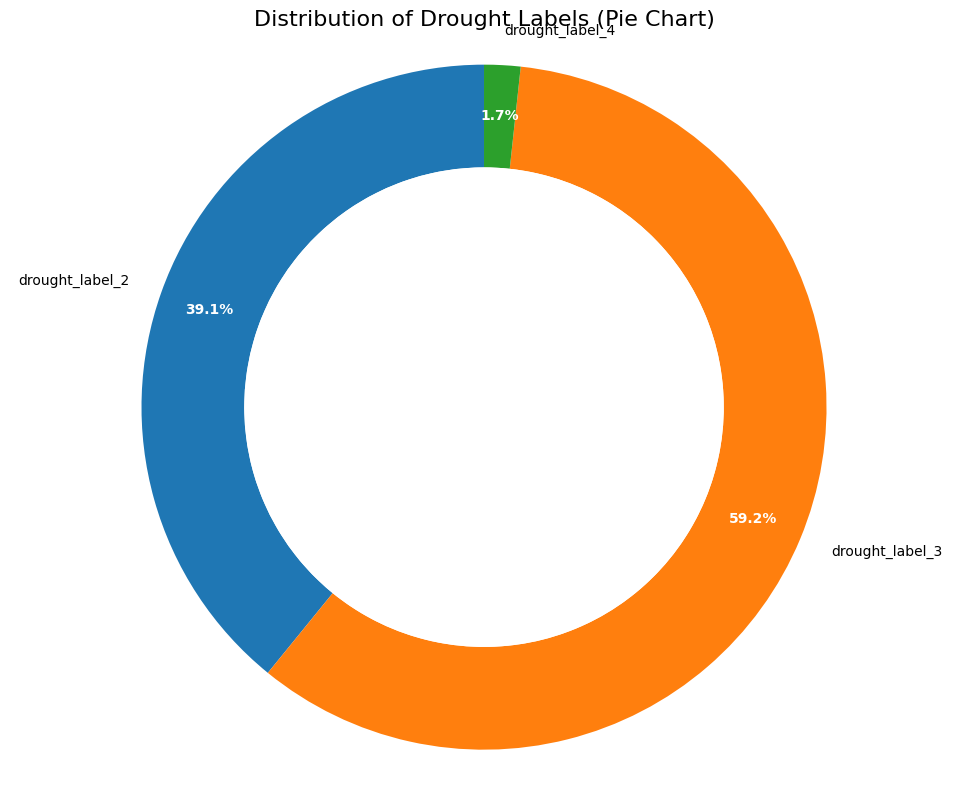

In [ ]:
import matplotlib.pyplot as plt

# Prepare data for the pie chart
labels = drought_label_counts_summary['drought_label_type']
sizes = drought_label_counts_summary['count_of_drought_labels']

# Create the pie chart
fig, ax = plt.subplots(figsize=(10, 8))
wedges, texts, autotexts = ax.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90,
                                  pctdistance=0.85, wedgeprops=dict(width=0.3))

# Draw a circle in the center to make it a donut chart
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Equal aspect ratio ensures that pie is drawn as a circle.
ax.axis('equal')

# Add title
ax.set_title('Distribution of Drought Labels (Pie Chart)', fontsize=16)

# Improve visibility of percentages
plt.setp(autotexts, size=10, weight="bold", color="white")
plt.setp(texts, size=10)

plt.tight_layout()
plt.show()

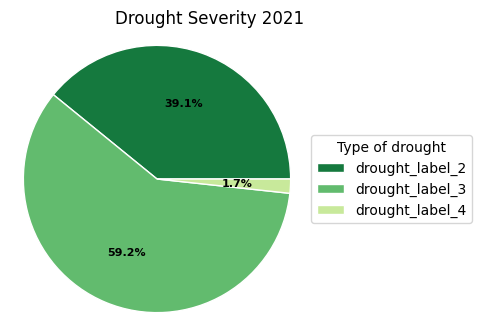

In [ ]:
plt.style.use('_mpl-gallery-nogrid')


# make data
x = drought_label_counts_summary['count_of_drought_labels']
labels = drought_label_counts_summary['drought_label_type']

colors = plt.get_cmap('YlGn_r')(np.linspace(0.2, 0.7, len(x)))

# plot
fig, ax = plt.subplots(figsize=(6, 3), subplot_kw=dict(aspect="equal"))

wedges, texts, autotexts = ax.pie(x, colors=colors, radius=3, center=(6, 6),
       wedgeprops={"linewidth": 1, "edgecolor": "white"}, frame=True, autopct='%1.1f%%')

plt.setp(autotexts, size=8, weight="bold")

ax.set_title("Drought Severity 2021", loc="right")

ax.legend(wedges, labels,
          title="Type of drought",
          loc="center left",
          bbox_to_anchor=(1, 0, 0.5, 1))

ax.axis('off') # Remove x and y axes

plt.show()

In [ ]:
# df_2021 = df_flattened[df_flattened['time'].dt.year == 2021]
df_2021.to_csv('df_2021.csv', index=False)

### Restarting Session
Run the cell below to programmatically restart the runtime session. This will clear the kernel memory. After running it, you can execute the authentication cell again.

In [ ]:
# This triggers a programmatic restart of the Google Colab session
import os
os._exit(0)